<a href="https://colab.research.google.com/github/umeaimanMerchant/CheatSheet-AI-ML-Concepts/blob/main/EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EDA and Feature Engineering


Source: https://www.krishnaik.in/ai-tutorials/eda-and-feature-engineering/



### Group 01: EDA Process & Pandas Fundamentals (00–05)
* EDA workflow and problem understanding
* Environment setup and dataset loading
* Dataset structure and initial inspection
* Pandas fundamentals and Copy-on-Write
* Text columns and common pandas traps

### Group 02: Reading & Auditing a Dataset (06–10)
* Reading different data formats
* Dataset dimensions and data types
* Descriptive statistics
* Unique values and value counts
* Data quality and initial auditing

### Group 03: Data Visualization & Charts (11–17)
* Univariate analysis
* Histograms and distribution plots
* Box plots and categorical plots
* Bivariate analysis
* Scatter plots and relationships
* Correlation heatmaps
* Choosing the right chart

### Group 04: Data Cleaning & Feature Engineering (18–39)
* **Missing Values (18–26)**
  * MCAR, MAR, and MNAR
  * Mean, median, and mode imputation
  * Random sample imputation
  * Missing indicators
  * Categorical missing-value strategies
* **Outlier Treatment (27–30)**
  * Z-score and IQR
  * Capping and trimming
  * Winsorization
* **Categorical Feature Engineering (31–39)**
  * Nominal vs. ordinal variables
  * One-hot encoding
  * Ordinal and label encoding
  * Count and frequency encoding
  * Target-guided ordinal encoding
  * Mean / target encoding
  * Handling unknown categories

### Group 05: Scaling, Transformation, Dates & Imbalance (40–56)
* **Feature Scaling (40–42)**
  * StandardScaler
  * MinMaxScaler
  * RobustScaler
* **Feature Transformation (43–47)**
  * Q-Q plots
  * Log and square-root transformations
  * Reciprocal transformation
  * Box-Cox and Yeo-Johnson
* **Date & Time Features (48–52)**
  * Date component extraction
  * Time and duration features
  * Date-based feature engineering
  * Cyclical encoding
* **Imbalanced Data (53–56)**
  * Class imbalance and evaluation metrics
  * Random undersampling and oversampling
  * SMOTE
  * Class weights and threshold tuning
  * Precision, recall, F1, and PR-AUC

### Group 06: Feature Selection & End-to-End ML Pipeline (57–71)
* **Feature Selection (57–62)**
  * Constant and quasi-constant features
  * Correlation-based selection
  * Mutual Information
  * Chi-square selection
  * Lasso-based selection
* **Leakage-Free ML Workflow (63–66)**
  * Understanding data leakage
  * Split first, then fit
  * ColumnTransformer
  * Pipeline and pandas output
* **House Price Prediction Project (67–71)**
  * Dataset and project setup
  * Exploratory data analysis
  * Feature engineering
  * Feature selection

In [ ]:
# ============================================================
# GROUP 01: THE PROCESS AND SETUP
# EDA & FEATURE ENGINEERING | Python 3.12+ | pandas 3.0+
# ============================================================

# ------------------------------------------------------------
# 1. INSTALLATION AND ENVIRONMENT SETUP
# ------------------------------------------------------------

import sys
import importlib
import subprocess

# Python 3.12+ is required for the library versions used here.
if sys.version_info < (3, 12):
    raise RuntimeError("Please use Python 3.12 or newer.")

# Install only missing libraries, using the same Python
# interpreter that runs this script.
packages = {
    "pandas": ("pandas", "3.0.6"),
    "numpy": ("numpy", "2.5.4"),
    "sklearn": ("scikit-learn", "1.9.1"),
    "matplotlib": ("matplotlib", "3.11.2"),
    "seaborn": ("seaborn", "0.13.2"),
    "scipy": ("scipy", "1.18.1"),
    "imblearn": ("imbalanced-learn", "0.14.2"),
    "openpyxl": ("openpyxl", "3.1.5")
}

for module, (package, version) in packages.items():
    try:
        importlib.import_module(module)
    except ImportError:
        subprocess.check_call([
            sys.executable, "-m", "pip", "install",
            f"{package}=={version}"
        ])

In [ ]:

# Import libraries.
import pandas as pd
import numpy as np
import sklearn
import matplotlib
import seaborn as sns
import scipy
import imblearn
import openpyxl
import warnings

# Verify the installed environment.
print("Python          :", sys.version.split()[0])
print("pandas          :", pd.__version__)
print("NumPy           :", np.__version__)
print("scikit-learn    :", sklearn.__version__)
print("Matplotlib      :", matplotlib.__version__)
print("Seaborn         :", sns.__version__)
print("SciPy           :", scipy.__version__)
print("imbalanced-learn:", imblearn.__version__)
print("openpyxl        :", openpyxl.__version__)

# Important:
# Install packages using sys.executable -m pip to avoid
# installing into a different Python environment.
# In Colab, use %pip install and restart the session
# if an already-loaded library has an older version.


Python          : 3.13.18
pandas          : 2.2.3
NumPy           : 2.4.6
scikit-learn    : 1.6.1
Matplotlib      : 3.10.0
Seaborn         : 0.13.2
SciPy           : 1.16.3
imbalanced-learn: 0.14.2
openpyxl        : 3.1.5


In [ ]:
# ------------------------------------------------------------
# 2. THE EDA AND FEATURE ENGINEERING PROCESS
# ------------------------------------------------------------

# EDA (Exploratory Data Analysis):
# Understand the dataset without modifying its contents.
# Output: observations, statistics, charts and data insights.

# Feature Engineering:
# Transform raw columns into useful features for ML models.
# Output: clean, transformed and model-ready data.

# Typical project workflow:
# Raw Data
#    -> EDA
#    -> Feature Engineering
#    -> Feature Selection
#    -> Model Creation
#    -> Hyperparameter Tuning
#    -> Deployment
#    -> Incremental Learning

# Six major feature engineering steps:
# 1. Explore data: distributions, data types, missing values,
#    categories and outliers.
# 2. Handle missing values: mean, median, mode, etc.
# 3. Handle target imbalance: undersampling, oversampling,
#    SMOTE or class weights.
# 4. Treat outliers: retain, cap or remove.
# 5. Scale numerical features: standardisation or normalisation.
# 6. Encode categorical features: convert categories to numbers.

# IMPORTANT:
# Inspect distributions and outliers before choosing an
# imputation strategy. Outliers can distort the mean.
# Also, fit preprocessing transformations on training data
# only, never on the complete dataset (data leakage).


In [ ]:

# ------------------------------------------------------------
# 3. LOAD THE COURSE DATASETS
# ------------------------------------------------------------

# Public datasets can be read directly from raw GitHub URLs.
# No manual download is required.

GH = "https://raw.githubusercontent.com/krishnaik06/"

# Titanic: missing values, outliers and scaling.
TITANIC = GH + "Feature-Engineering-Live-sessions/master/titanic.csv"
titanic = pd.read_csv(TITANIC)

# Ames Housing: feature selection, correlation and prediction.
AMES = GH + "Advanced-House-Price-Prediction-/master/train.csv"
ames = pd.read_csv(AMES)

# Mobile Price: classification and feature selection.
MOBILE = GH + "Feature-Engineering-Live-sessions/master/mobile_dataset.csv"
mobile = pd.read_csv(MOBILE)

# Mercedes: high-cardinality categorical features.
# usecols avoids loading all 378 columns when only two are needed.
MERCEDES = GH + "Feature-Engineering-Live-sessions/master/mercedes.csv"
mercedes = pd.read_csv(MERCEDES, usecols=["X1", "X2"])

# Print dataset dimensions.
for name, df in [
    ("Titanic", titanic),
    ("Ames", ames),
    ("Mobile", mobile),
    ("Mercedes", mercedes)
]:
    print(f"{name:12} {df.shape[0]:5} rows x {df.shape[1]:2} columns")

# Expected dimensions:
# Titanic   : 891 x 12
# Ames      : 1460 x 81
# Mobile    : 2000 x 21
# Mercedes  : 4209 x 2

# Flight Fare dataset: date, time and duration engineering.
# read_excel requires openpyxl.
FLIGHT = (
    "https://raw.githubusercontent.com/krishnaik06/"
    "5-Days-Live-EDA-and-Feature-Engineering/main/Flight%20Prediction/"
)

flight_train = pd.read_excel(FLIGHT + "Data_Train.xlsx")
flight_test = pd.read_excel(FLIGHT + "Test_set.xlsx")

print("Flight train:", flight_train.shape)  # 10683 x 11
print("Flight test :", flight_test.shape)   # 2671 x 10

# Train has the Price target; test does not.
# %20 represents a space in a URL.
# The course also uses a Zomato ZIP containing multiple files,
# which will be handled in the CSV reading section.


Titanic        891 rows x 12 columns
Ames          1460 rows x 81 columns
Mobile        2000 rows x 21 columns
Mercedes      4209 rows x  2 columns
Flight train: (10683, 11)
Flight test : (2671, 10)


In [ ]:
# ------------------------------------------------------------
# 4. PANDAS COPY-ON-WRITE AND CHAINED ASSIGNMENT
# ------------------------------------------------------------

# Pandas 3.0 makes Copy-on-Write permanent.
# Selecting an intermediate Series/DataFrame and modifying it
# does not automatically modify the original DataFrame.

df = pd.read_csv(TITANIC, usecols=["Survived", "Age", "Fare"])

print("Missing Age before:", df["Age"].isna().sum())

# OLD / INCORRECT:
# This modifies an intermediate Series, not the original df.
# The missing values remain unchanged in pandas 3.0.
# ChainedAssignmentError is a warning by default.

try:
    with warnings.catch_warnings():
        warnings.simplefilter(
            "error", pd.errors.ChainedAssignmentError
        )
        df["Age"].fillna(df["Age"].median(), inplace=True)
except pd.errors.ChainedAssignmentError:
    print("Chained assignment detected!")

print("Missing Age after incorrect fill:", df["Age"].isna().sum())

# CORRECT APPROACH 1:
# Assign the transformed Series back to the original column.
df["Age"] = df["Age"].fillna(df["Age"].median())

print("Missing Age after correct fill:", df["Age"].isna().sum())

# CORRECT APPROACH 2:
# Apply fillna directly to the DataFrame using a dictionary.
other = pd.read_csv(TITANIC, usecols=["Survived", "Age", "Fare"])
other.fillna({"Age": other["Age"].median()}, inplace=True)

print("Missing Age using frame-level fill:", other["Age"].isna().sum())

# CORRECT APPROACH 3:
# Use .loc to select rows and columns together.
df = pd.read_csv(TITANIC, usecols=["Survived", "Age", "Fare"])

missing_age = df["Age"].isna()
df.loc[missing_age, "Fare"] = 0.0

# Avoid chained writes such as:
# df[missing_age]["Fare"] = 0
# df["Fare"][missing_age] = 0

# Enable strict checking so chained assignments stop execution
# instead of producing a warning that may go unnoticed.
warnings.simplefilter(
    "error", pd.errors.ChainedAssignmentError
)

# Rule:
# Never use inplace=True on an intermediate object from df[...].
# Use df["column"] = df["column"].method(...)
# or df.loc[row_mask, "column"] = value.


Missing Age before: 177
Missing Age after incorrect fill: 0
Missing Age after correct fill: 0
Missing Age using frame-level fill: 0


/tmp/ipykernel_5664/4208130261.py:23: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["Age"].fillna(df["Age"].median(), inplace=True)


In [ ]:

# ------------------------------------------------------------
# 5. PANDAS 3.0: TEXT COLUMNS AND THE STR DTYPE
# ------------------------------------------------------------

# Older pandas versions stored text columns as object ('O').
# Pandas 3.0 gives string columns their own str dtype.

print("MSZoning dtype:", ames["MSZoning"].dtype)
print("First categories:", ames["MSZoning"].unique()[:3])

# OLD / INCORRECT:
# This test used to identify categorical text columns.
# In pandas 3.0, it returns False for str columns.

old_categorical = [
    col for col in ames.columns
    if ames[col].dtype == "O"
]

print("Old categorical count:", len(old_categorical))  # 0

# This causes a silent classification error:
# All 81 columns may incorrectly be treated as numerical.
old_numerical = [
    col for col in ames.columns
    if ames[col].dtype != "O"
]

print("Old numerical count:", len(old_numerical))  # 81

# CORRECT APPROACH 1:
# select_dtypes identifies columns based on their data types.
categorical = ames.select_dtypes(include=["object"]).columns.tolist()
numerical = ames.select_dtypes(include=["number"]).columns.tolist()

print("Categorical:", len(categorical))  # 43
print("Numerical  :", len(numerical))    # 38

# CORRECT APPROACH 2:
# Type-checking functions are useful when iterating over columns.
# is_string_dtype also supports older object-based text columns.
is_text = pd.api.types.is_string_dtype
is_numeric = pd.api.types.is_numeric_dtype

categorical = [col for col in ames.columns if is_text(ames[col])]
numerical = [col for col in ames.columns if is_numeric(ames[col])]

print("Categorical:", len(categorical))
print("Numerical  :", len(numerical))

# IMPORTANT:
# A categorical dtype is different from str.
# select_dtypes(include="str") does not include category columns.
# Include both when your dataset uses pandas categorical dtype.
categorical_all = ames.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# object: can hold arbitrary Python objects or mixed values.
# str: dedicated text dtype in pandas 3.0.
# category: stores values from a fixed set of categories.

# A wrong dtype check can silently send text columns to a scaler.
# The eventual error may appear much later:
# ValueError: could not convert string to float: 'RL'

# Always validate the number of columns detected before
# applying encoding or scaling transformations.

print("Final dtype counts:")
print(ames.dtypes.value_counts())


MSZoning dtype: object
First categories: ['RL' 'RM' 'C (all)']
Old categorical count: 43
Old numerical count: 38
Categorical: 43
Numerical  : 38
Categorical: 27
Numerical  : 38
Final dtype counts:
object     43
int64      35
float64     3
Name: count, dtype: int64


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Age       714 non-null    float64
 2   Fare      891 non-null    float64
dtypes: float64(2), int64(1)
memory usage: 21.0 KB


In [ ]:
# ============================================================
# GROUP 02: READING AND AUDITING A DATASET
# EDA & FEATURE ENGINEERING | pandas 3.0+
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import io
import zipfile
import urllib.request


# ------------------------------------------------------------
# 1. READING A CSV WITH NON-UTF-8 ENCODING
# ------------------------------------------------------------

# UTF-8 is pandas' default encoding.
# Older systems and Excel exports may use CP1252 or Latin-1.

ZIP_URL = (
    "https://raw.githubusercontent.com/krishnaik06/"
    "5-Days-Live-EDA-and-Feature-Engineering/main/Zomatodataset.zip"
)

# Download the ZIP into memory instead of saving it to disk.
# BytesIO converts downloaded bytes into a file-like object.
zip_bytes = urllib.request.urlopen(ZIP_URL).read()
zf = zipfile.ZipFile(io.BytesIO(zip_bytes))

# List files inside the archive.
# namelist() returns filenames; getinfo() provides file metadata.
for name in zf.namelist():
    print(f"{zf.getinfo(name).file_size:>10,} bytes | {name}")

# IMPORTANT:
# pd.read_csv() can automatically open a ZIP containing one CSV.
# If multiple files exist, pandas cannot decide which one to read.
# Open the required member explicitly.

# UTF-8: default encoding; may fail on invalid byte sequences.
# CP1252: common Windows encoding; may also fail on some bytes.
# Latin-1: maps all 256 byte values, so it never raises a decoding
# error, but it can silently produce incorrect characters.

for encoding in ["utf-8", "cp1252", "latin-1"]:
    try:
        with zf.open("zomato.csv") as fh:
            temp = pd.read_csv(fh, encoding=encoding)

        print(encoding, "SUCCESS:", temp.shape)

    except UnicodeDecodeError as error:
        print(encoding, "FAILED:", error)

# Latin-1 successfully reads this particular dataset.
# Always inspect accented names after decoding.
# A successful read does not guarantee correct text.

with zf.open("zomato.csv") as fh:
    df = pd.read_csv(fh, encoding="latin-1")

print(df.shape)  # (9551, 21)

# Read the Excel lookup table from the same ZIP.
# read_excel uses openpyxl to read .xlsx files.
with zf.open("Country-Code.xlsx") as fh:
    codes = pd.read_excel(fh)



     8,783 bytes | Country-Code.xlsx
 2,198,732 bytes | file1.json
20,006,072 bytes | file2.json
15,610,388 bytes | file3.json
16,427,749 bytes | file4.json
   669,503 bytes | file5.json
        72 bytes | Untitled.ipynb
 2,257,316 bytes | zomato.csv
utf-8 FAILED: 'utf-8' codec can't decode byte 0xed in position 7044: invalid continuation byte
cp1252 FAILED: 'charmap' codec can't decode byte 0x81 in position 9144: character maps to <undefined>
latin-1 SUCCESS: (9551, 21)
(9551, 21)


In [ ]:
# ------------------------------------------------------------
# 2. THE FIRST LOOK AT A DATASET
# ------------------------------------------------------------

# STEP 1: Shape tells us the number of rows and columns.
print("Shape:", df.shape)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# STEP 2: Inspect the first and last observations.
# head() and tail() return five rows by default.
print(df.head(3))
print(df.tail(3))

# STEP 3: Inspect column names.
# Prefer bracket notation because column names may contain spaces.
print(df.columns.tolist())

# STEP 4: Inspect data types, non-null counts and memory usage.
print(df.info())

# Deep memory usage includes the memory occupied by objects
# and strings, not just the underlying array references.
# print("Memory usage:", df.memory_usage(deep=True).sum() / 1024**2, "MB")

# STEP 5: Count columns by data type.
print(df.dtypes.value_counts())

# STEP 6: Statistical summary of numerical columns.
# Includes count, mean, std, min, quartiles and max.
print(df.describe().round(2))

# STEP 7: Statistical summary of text columns.
# count = non-null entries
# unique = number of distinct values
# top = most frequent value
# freq = frequency of the most frequent value
print(df.describe(include="object"))

# IMPORTANT:
# describe() summarizes numerical columns by default.
# It does not summarize every column automatically.

# A column stored as an integer may actually be categorical.
# Example: Price range has values 1, 2, 3 and 4.
# These numbers represent categories, not continuous measurements.

# Check category-like numerical columns separately.
print(df["Price range"].value_counts())

# Check unusual numerical values.
# Example: a rating of zero may mean "not rated", not a bad rating.
print(df["Aggregate rating"].value_counts().sort_index().head(5))

# Use to_string() when you want to prevent pandas from
# truncating a printed DataFrame or Series.


Shape: (9551, 21)
Rows: 9551
Columns: 21
   Restaurant ID         Restaurant Name  Country Code              City  \
0        6317637        Le Petit Souffle           162       Makati City   
1        6304287        Izakaya Kikufuji           162       Makati City   
2        6300002  Heat - Edsa Shangri-La           162  Mandaluyong City   

                                             Address  \
0  Third Floor, Century City Mall, Kalayaan Avenu...   
1  Little Tokyo, 2277 Chino Roces Avenue, Legaspi...   
2  Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...   

                                     Locality  \
0   Century City Mall, Poblacion, Makati City   
1  Little Tokyo, Legaspi Village, Makati City   
2  Edsa Shangri-La, Ortigas, Mandaluyong City   

                                    Locality Verbose   Longitude   Latitude  \
0  Century City Mall, Poblacion, Makati City, Mak...  121.027535  14.565443   
1  Little Tokyo, Legaspi Village, Makati City, Ma...  121.014101  14.55370

Total missing cells: 9
Cuisines    9
dtype: int64
Missing percentage:
Cuisines    0.09
dtype: float64
0    9542
1       9
Name: count, dtype: int64


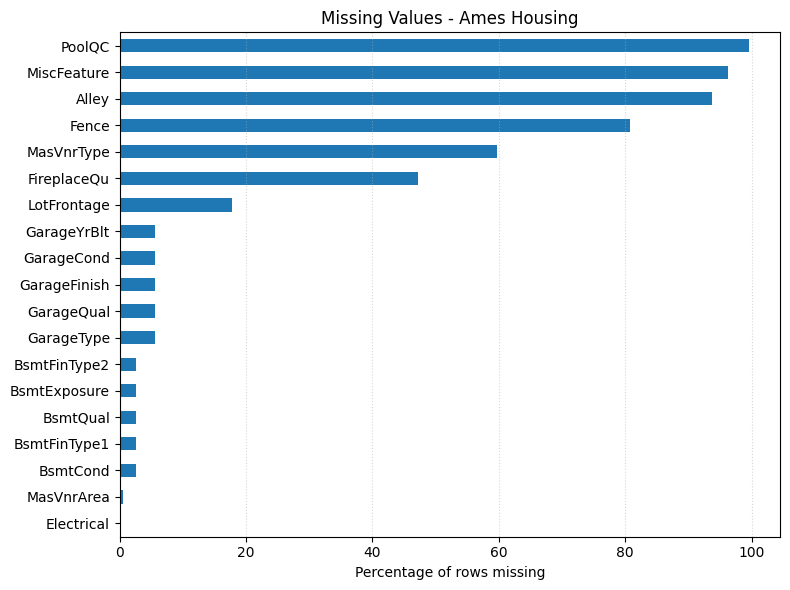

Cuisines
North Indian             936
North Indian, Chinese    511
Fast Food                354
Chinese                  354
North Indian, Mughlai    334
Name: count, dtype: int64
Full-row duplicates: 0
Duplicates, keeping first: 111
Duplicates, keeping last: 111
All rows with duplicates: 167
     PassengerId  Survived  Pclass                           Name   Sex   Age  \
252          253         0       1      Stead, Mr. William Thomas  male  62.0   
555          556         0       1             Wright, Mr. George  male  62.0   
633          634         0       1  Parr, Mr. William Henry Marsh  male   NaN   
815          816         0       1               Fry, Mr. Richard  male   NaN   
64            65         0       1          Stewart, Mr. Albert A  male   NaN   
295          296         0       1              Lewy, Mr. Ervin G  male   NaN   
144          145         0       2     Andrew, Mr. Edgardo Samuel  male  18.0   
757          758         0       2       Bailey, Mr. Percy

In [ ]:

# ------------------------------------------------------------
# 3. THE MISSING VALUE MAP
# ------------------------------------------------------------

# isnull() / isna() returns True for missing values.
# True is treated as 1 and False as 0 during summation.

# Total missing cells across the entire dataset.
print("Total missing cells:", df.isnull().sum().sum())

# Count missing values column by column.
missing_count = df.isnull().sum()

# Keep only columns containing missing values.
missing_count = missing_count[missing_count > 0]
print(missing_count)

# Missing-value percentage.
# mean() calculates the proportion of True values.
missing_share = df.isnull().mean()

# Sort columns by highest missing percentage.
missing_share = missing_share[missing_share > 0].sort_values(
    ascending=False
)

print("Missing percentage:")
print((missing_share * 100).round(2))

# Count missing values row by row.
print(df.isnull().sum(axis=1).value_counts().head())

# VISUALIZATION:
# Use a horizontal bar chart to compare missing-value percentages.
# A heatmap can become difficult to read for large datasets.

# Ames Housing dataset has 19 columns with missing values.
AMES_URL = (
    "https://raw.githubusercontent.com/krishnaik06/"
    "Advanced-House-Price-Prediction-/master/train.csv"
)

ames = pd.read_csv(AMES_URL)

ames_missing = ames.isnull().mean()
ames_missing = ames_missing[ames_missing > 0].sort_values()

fig, ax = plt.subplots(figsize=(8, 6))

(ames_missing * 100).plot.barh(ax=ax)

ax.set_xlabel("Percentage of rows missing")
ax.set_title("Missing Values - Ames Housing")
ax.grid(axis="x", linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

# IMPORTANT:
# Missing percentage helps decide what to investigate next.
# A column with 99% missing values may not be worth retaining.
# A column with 17% missing values may need imputation.
# But do not use a fixed percentage threshold blindly.

# Missing values may carry information.
# Example: an empty Garage column may mean the house has no garage,
# rather than the information being accidentally lost.

# pandas does not automatically treat every placeholder as NaN.
# Examples: '?', 'NA', 'unknown', -1 and sometimes 0.

# Detect suspicious placeholders using value_counts().
print(df["Cuisines"].value_counts(dropna=False).head())

# Convert known placeholders into actual missing values at read time:
# df = pd.read_csv(
#     "data.csv",
#     na_values=["?", "unknown", "NA", -1]
# )

# Be careful: -1 and 0 may be valid values in some datasets.
# Only define placeholders after understanding the data.



# ------------------------------------------------------------
# 5. FINDING AND HANDLING DUPLICATES
# ------------------------------------------------------------

TITANIC_URL = (
    "https://raw.githubusercontent.com/krishnaik06/"
    "Feature-Engineering-Live-sessions/master/titanic.csv"
)

titanic = pd.read_csv(TITANIC_URL)

# Check exact duplicate rows across all columns.
# duplicated() marks the second and subsequent occurrences.
print("Full-row duplicates:", titanic.duplicated().sum())

# IMPORTANT:
# An ID column is usually unique.
# Therefore, checking every column may return zero duplicates
# even when two observations have identical model features.

# Select only the columns relevant to a Titanic prediction model.
features = [
    "Survived", "Pclass", "Sex", "Age",
    "SibSp", "Parch", "Fare", "Embarked"
]

# keep='first': mark copies after the first occurrence.
print("Duplicates, keeping first:",
      titanic.duplicated(subset=features, keep="first").sum())

# keep='last': mark copies before the last occurrence.
print("Duplicates, keeping last:",
      titanic.duplicated(subset=features, keep="last").sum())

# keep=False: mark ALL rows belonging to duplicate groups,
# including the original occurrence.
print("All rows with duplicates:",
      titanic.duplicated(subset=features, keep=False).sum())

# Inspect duplicate-looking observations before deleting anything.
duplicate_rows = titanic[
    titanic.duplicated(subset=features, keep=False)
]

print(duplicate_rows.sort_values(features).head(10))

# NaN values are treated as matching during duplicated() checks.
# Two rows with missing Age and identical remaining features
# can therefore be marked as duplicates.

# REMOVE DUPLICATES:
# Only do this when repeated rows represent the same record
# ingested more than once, not two legitimate observations.
deduped = titanic.drop_duplicates(
    subset=features,
    keep="first",
    ignore_index=True
)

print("Before:", titanic.shape)
print("After :", deduped.shape)
print("Rows removed:", len(titanic) - len(deduped))

# Verify that the selected duplicate definition is now satisfied.
print("Duplicates remaining:",
      deduped.duplicated(subset=features).sum())

# IMPORTANT:
# Titanic has 111 repeated feature combinations.
# But these can represent different passengers with identical
# characteristics. Removing all 111 would delete valid records.
# Duplicate-looking observations are not automatically errors.




In [ ]:

# ------------------------------------------------------------
# 4. MERGING A LOOKUP TABLE
# ------------------------------------------------------------

# A lookup table translates codes into meaningful descriptions.
# Example: Country Code = 1 -> Country = India.

# Inspect the lookup table before merging.
print(codes.shape)
print(codes.head())

# Both DataFrames must have compatible join-key names and types.
print(df["Country Code"].dtype)
print(codes["Country Code"].dtype)

# Check whether the lookup key is unique.
# A country code should map to only one country.
print("Unique lookup keys:", codes["Country Code"].is_unique)

# LEFT JOIN:
# Keep every row from the main dataset and add matching country names.
# validate='many_to_one' ensures each left key matches at most
# one row in the lookup table.
final_df = df.merge(
    codes,
    on="Country Code",
    how="left",
    validate="many_to_one",
    indicator=True
)

print("Before merge:", df.shape)
print("After merge :", final_df.shape)

# Check whether any country code failed to match.
print(final_df["Country"].isnull().sum())

# indicator=True adds _merge:
# both       -> matched on both sides
# left_only  -> found only in the main dataset
# right_only -> found only in the lookup dataset
print(final_df["_merge"].value_counts())

# Remove the audit column once validation is complete.
final_df = final_df.drop(columns="_merge")

# OTHER JOIN TYPES:
# left  : all rows from left + matching rows from right.
# inner : only rows with matches on both sides.
# right : all rows from right + matching rows from left.
# outer : all rows from both sides.

# Demonstrate the difference using an incomplete lookup.
three = codes.head(3)

for how in ["left", "inner", "right", "outer"]:
    merged = df.merge(three, on="Country Code", how=how)
    print(how, merged.shape)

# IMPORTANT:
# An inner join can silently remove unmatched rows.
# A left join preserves the main dataset's rows.

# A many-to-many or incorrect lookup can multiply rows.
# Example: if one country code appears twice in the lookup,
# every matching restaurant may appear twice after merging.

# validate options:
# one_to_one   : keys unique in both DataFrames.
# one_to_many  : keys unique in left DataFrame.
# many_to_one  : keys unique in right DataFrame.
# many_to_many : allows repeated keys on both sides.

# Correct a misspelled value in the merged lookup column.
final_df["Country"] = final_df["Country"].replace({
    "Phillipines": "Philippines"
})


(15, 2)
   Country Code    Country
0             1      India
1            14  Australia
2            30     Brazil
3            37     Canada
4            94  Indonesia
int64
int64
Unique lookup keys: True
Before merge: (9551, 21)
After merge : (9551, 23)
0
_merge
both          9551
left_only        0
right_only       0
Name: count, dtype: int64
left (9551, 22)
inner (8736, 22)
right (8736, 22)
outer (9551, 22)


In [ ]:
# ------------------------------------------------------------
# 6. DUPLICATE ROWS VS DUPLICATE INDEX LABELS
# ------------------------------------------------------------

# Duplicate rows = repeated values in the data.
# Duplicate index = repeated row labels, a different problem.

# Read train and test datasets with common columns.
AMES_BASE = (
    "https://raw.githubusercontent.com/krishnaik06/"
    "Advanced-House-Price-Prediction-/master/"
)

train = pd.read_csv(
    AMES_BASE + "train.csv",
    usecols=["Id", "MSZoning", "LotArea"]
)

test = pd.read_csv(
    AMES_BASE + "test.csv",
    usecols=["Id", "MSZoning", "LotArea"]
)

# pd.concat() stacks DataFrames vertically by default.
# It preserves the original index labels unless instructed otherwise.
stacked = pd.concat([train, test])

print("Rows:", len(stacked))
print("Index unique:", stacked.index.is_unique)

# Duplicate index labels can cause .loc to return multiple rows.
print("Rows with index label 5:", len(stacked.loc[5]))

# drop(5) removes every row with index label 5, not just one.
print("After dropping index label 5:", len(stacked.drop(5)))

# CORRECT APPROACH:
# ignore_index=True generates a fresh continuous index.
clean_stacked = pd.concat(
    [train, test],
    ignore_index=True
)

print("Rows:", len(clean_stacked))
print("Index unique:", clean_stacked.index.is_unique)

# reset_index(drop=True) can also create a fresh index.
clean_stacked = clean_stacked.reset_index(drop=True)

# IMPORTANT:
# df.index.is_unique checks index labels, not duplicate records.
# df.duplicated() checks repeated records, not index labels.
# Do not confuse these two checks.



Rows: 2919
Index unique: False
Rows with index label 5: 2
After dropping index label 5: 2917
Rows: 2919
Index unique: True


In [ ]:

# ------------------------------------------------------------
# FINAL: REPEATABLE DATA AUDIT CHECKLIST
# ------------------------------------------------------------

def audit_dataframe(data):
    print("\n========== DATA AUDIT ==========")

    # Dataset size.
    print("\nShape:", data.shape)

    # Column data types.
    print("\nData types:")
    print(data.dtypes.value_counts())

    # Missing values.
    missing = data.isnull().sum()
    missing = missing[missing > 0]

    print("\nMissing values:")
    print(missing if not missing.empty else "None")

    # Missing-value percentages.
    print("\nMissing percentages:")
    print((data.isnull().mean() * 100).round(2).loc[
        lambda x: x > 0
    ])

    # Exact duplicate records.
    print("\nFull-row duplicates:", data.duplicated().sum())

    # Index uniqueness.
    print("Index unique:", data.index.is_unique)

    # Memory consumption.
    print("Memory (MB):",
          round(data.memory_usage(deep=True).sum() / 1024**2, 2))

    print("\n========== END AUDIT ==========")


audit_dataframe(df)



========== DATA AUDIT ==========

Shape: (9551, 21)

Data types:
object     13
int64       5
float64     3
Name: count, dtype: int64

Missing values:
Cuisines    9
dtype: int64

Missing percentages:
Cuisines    0.09
dtype: float64

Full-row duplicates: 0
Index unique: True
Memory (MB): 7.98

========== END AUDIT ==========


In [ ]:
# ============================================================
# GROUP 03: CHARTS THAT ANSWER A QUESTION
# EDA & FEATURE ENGINEERING | pandas 3.0 | seaborn 0.13
# ============================================================

# ------------------------------------------------------------
# 1. SETUP AND LOAD DATA
# ------------------------------------------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import io
import zipfile
import urllib.request

sns.set_theme(style="whitegrid")

# Load Zomato dataset from ZIP.
URL = (
    "https://raw.githubusercontent.com/krishnaik06/"
    "5-Days-Live-EDA-and-Feature-Engineering/main/Zomatodataset.zip"
)

zf = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(URL).read()))

with zf.open("zomato.csv") as file:
    zomato = pd.read_csv(file, encoding="latin-1")

with zf.open("Country-Code.xlsx") as file:
    country_codes = pd.read_excel(file)

# Merge country names into the restaurant dataset.
zomato = zomato.merge(
    country_codes,
    on="Country Code",
    how="left",
    validate="many_to_one"
)

# Load Titanic for numerical analysis.
TITANIC_URL = (
    "https://raw.githubusercontent.com/krishnaik06/"
    "Feature-Engineering-Live-sessions/master/titanic.csv"
)

titanic = pd.read_csv(TITANIC_URL)



Rating text
Average      3737
Not rated    2148
Good         2100
Very Good    1079
Excellent     301
Poor          186
Name: count, dtype: int64
Rating text
Average      39.13
Not rated    22.49
Good         21.99
Very Good    11.30
Excellent     3.15
Poor          1.95
Name: proportion, dtype: float64


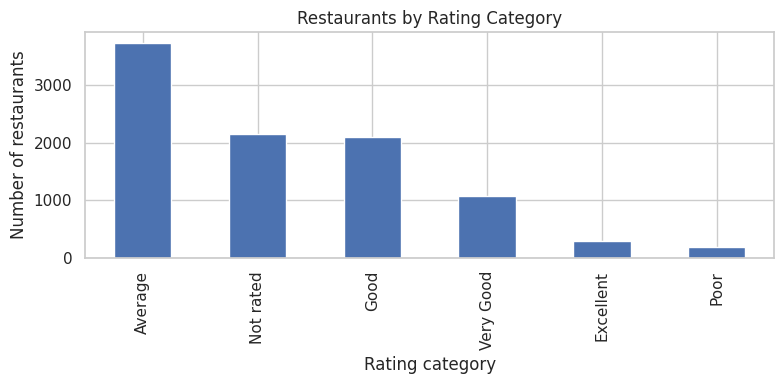

In [ ]:

# ------------------------------------------------------------
# 2. ONE CHART, ONE QUESTION, ONE OBSERVATION
# ------------------------------------------------------------

# Start with a business or analytical question.
# Example: How many restaurants fall into each rating category?

# Count restaurants by rating category.
ratings = zomato["Rating text"].value_counts()

print(ratings)

# Calculate the percentage of total restaurants in each category.
rating_share = zomato["Rating text"].value_counts(normalize=True) * 100

print(rating_share.round(2))

# Plot the counts.
fig, ax = plt.subplots(figsize=(8, 4))

ratings.plot.bar(ax=ax)

ax.set_xlabel("Rating category")
ax.set_ylabel("Number of restaurants")
ax.set_title("Restaurants by Rating Category")

plt.tight_layout()
plt.show()

# OBSERVATION:
# Average is the largest rating category.
# Not rated represents a significant portion of the dataset.
# Excellent and Poor are relatively rare.

# A chart is not the final output.
# Write the observation next to the chart in your notebook.
# The chart provides evidence; the sentence communicates the finding.


Country
India             8652
United States      434
United Kingdom      80
Brazil              60
South Africa        60
UAE                 60
New Zealand         40
Turkey              34
Australia           24
Phillipines         22
Name: count, dtype: int64
Index(['India', 'United States', 'United Kingdom', 'Brazil', 'South Africa',
       'UAE', 'New Zealand', 'Turkey', 'Australia', 'Phillipines', 'Indonesia',
       'Qatar', 'Singapore', 'Sri Lanka', 'Canada'],
      dtype='object', name='Country')
[8652  434   80   60   60   60   40   34   24   22   21   20   20   20
    4]
Country
India             0.905874
United States     0.045440
United Kingdom    0.008376
Brazil            0.006282
South Africa      0.006282
Name: proportion, dtype: float64
Cuisines
North Indian             936
North Indian, Chinese    511
Fast Food                354
Chinese                  354
North Indian, Mughlai    334
Name: count, dtype: int64
Rating text
Excellent     301
Very Good    1079
Good  

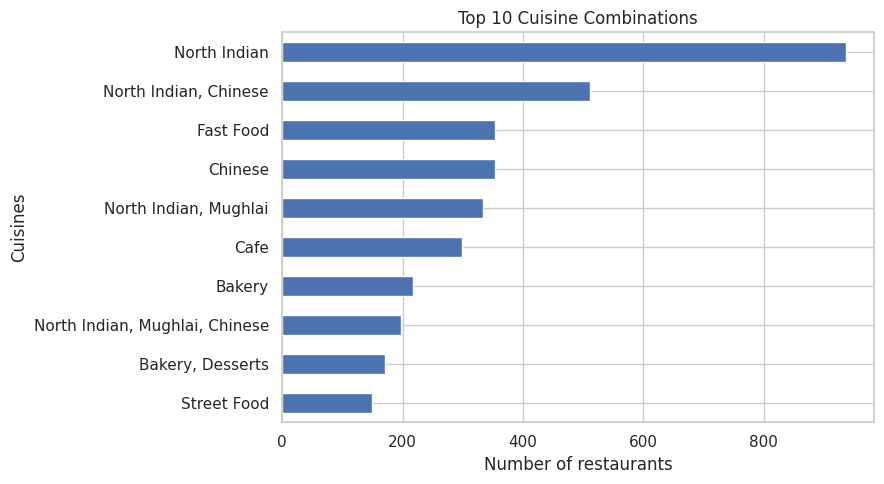

In [ ]:
# ------------------------------------------------------------
# 3. COUNTING CATEGORIES WITH value_counts()
# ------------------------------------------------------------

# value_counts() returns a Series:
# Index = unique categories
# Values = frequency of each category
# Default = descending frequency, excludes NaN.

country_counts = zomato["Country"].value_counts()

print(country_counts.head(10))

# Access category labels and their corresponding counts.
print(country_counts.index)
print(country_counts.values)

# normalize=True returns proportions instead of counts.
print(zomato["Country"].value_counts(normalize=True).head())

# dropna=False includes missing values as a separate category.
print(zomato["Cuisines"].value_counts(dropna=False).head())

# sort=False preserves the order in which values appear.
print(zomato["Rating text"].value_counts(sort=False))

# Count unique categories, including missing values.
print("Unique values:", zomato["Cuisines"].nunique(dropna=False))

# TOP 10 MOST COMMON CUISINES:
# head(10) selects the ten most frequent categories.
top_cuisines = zomato["Cuisines"].value_counts().head(10)

# Horizontal bars are useful when category labels are long.
# Sort ascending so the largest bar appears at the top.
fig, ax = plt.subplots(figsize=(9, 5))

top_cuisines.sort_values().plot.barh(ax=ax)

ax.set_xlabel("Number of restaurants")
ax.set_title("Top 10 Cuisine Combinations")

plt.tight_layout()
plt.show()

# IMPORTANT:
# Cuisines contains comma-separated combinations.
# "North Indian, Chinese" is one category, not two.
# Split the column before counting individual cuisines.
# Also, equal-frequency categories should not be interpreted
# as having a meaningful ranking.


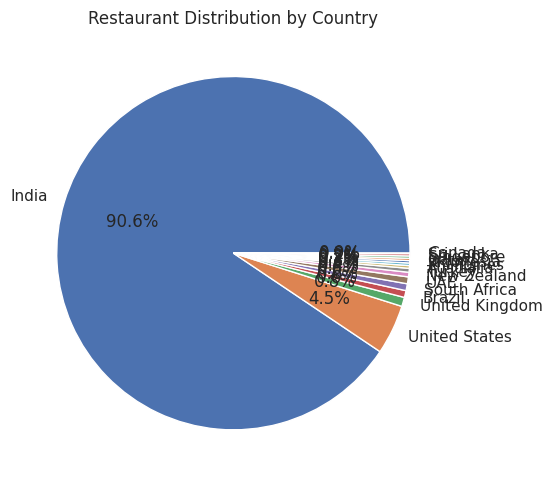

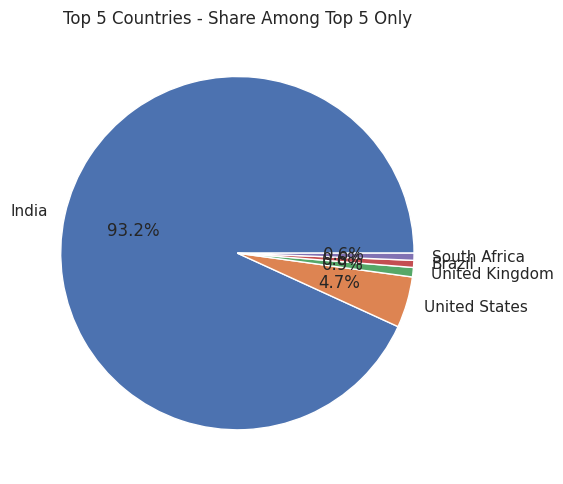

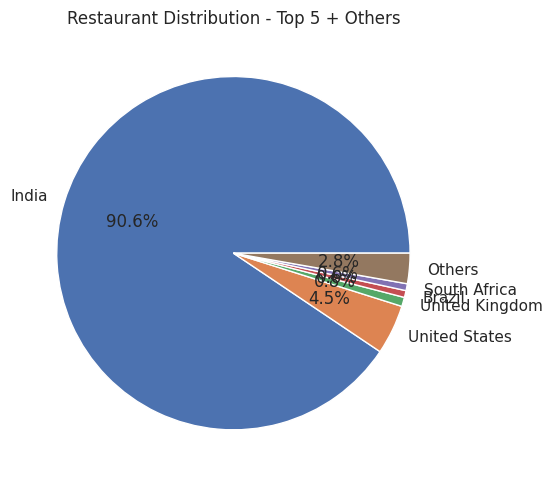

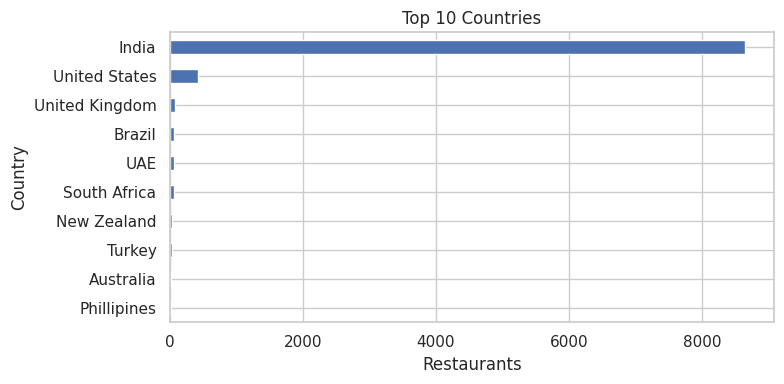

In [ ]:
# ------------------------------------------------------------
# 4. PIE AND BAR CHARTS WITH TOP-N TRIM
# ------------------------------------------------------------

# A pie chart represents proportions of a whole.
# It works best when there are only a few categories.

country_counts = zomato["Country"].value_counts()

# Plot all countries.
fig, ax = plt.subplots(figsize=(7, 5))

ax.pie(
    country_counts.values,
    labels=country_counts.index,
    autopct="%1.1f%%"
)

ax.set_title("Restaurant Distribution by Country")

plt.tight_layout()
plt.show()

# PROBLEM:
# Too many categories create overlapping labels and tiny slices.

# Keep only the top five countries.
top5 = country_counts.head(5)

fig, ax = plt.subplots(figsize=(7, 5))

ax.pie(
    top5.values,
    labels=top5.index,
    autopct="%1.1f%%"
)

ax.set_title("Top 5 Countries - Share Among Top 5 Only")

plt.tight_layout()
plt.show()

# IMPORTANT:
# The percentages above are calculated against the top five total,
# NOT the complete dataset.

# BETTER APPROACH:
# Combine the remaining countries into an "Others" category.
# This preserves the entire dataset's denominator.
top5_with_others = pd.concat([
    top5,
    pd.Series({
        "Others": country_counts.iloc[5:].sum()
    })
])

fig, ax = plt.subplots(figsize=(7, 5))

ax.pie(
    top5_with_others.values,
    labels=top5_with_others.index,
    autopct="%1.1f%%"
)

ax.set_title("Restaurant Distribution - Top 5 + Others")

plt.tight_layout()
plt.show()

# BAR CHART:
# Prefer bar charts when comparing many categories.
fig, ax = plt.subplots(figsize=(8, 4))

country_counts.head(10).sort_values().plot.barh(ax=ax)

ax.set_xlabel("Restaurants")
ax.set_title("Top 10 Countries")

plt.tight_layout()
plt.show()

# Rule:
# Pie chart -> few categories and part-to-whole comparison.
# Bar chart -> ranking and comparison across categories.


In [ ]:

# ------------------------------------------------------------
# 5. ANSWERING QUESTIONS WITH groupby()
# ------------------------------------------------------------

# value_counts() counts one column.
# groupby() lets us answer questions involving multiple columns.

# Question:
# How many restaurants belong to each rating text and rating color?

# groupby() creates groups but does not calculate anything yet.
grouped = zomato.groupby(["Rating text", "Rating color"])

# size() counts rows in each group.
rating_summary = grouped.size()

print(rating_summary)

# reset_index() converts the grouped result into a DataFrame.
# rename() gives the count column a meaningful name.
rating_summary = (
    rating_summary
    .reset_index(name="Restaurant Count")
)

print(rating_summary)

# Question:
# What is the average rating for each country?
country_rating = (
    zomato.groupby("Country")
    ["Aggregate rating"]
    .agg(["mean", "median", "min", "max", "count"])
    .sort_values("mean", ascending=False)
)

print(country_rating.round(2))

# Multiple aggregations can be applied to different columns.
# Named aggregation produces cleaner column names.
country_summary = (
    zomato.groupby("Country")
    .agg(
        restaurant_count=("Restaurant ID", "count"),
        average_rating=("Aggregate rating", "mean"),
        average_votes=("Votes", "mean")
    )
    .sort_values("restaurant_count", ascending=False)
)

print(country_summary.head(10))

# Grouping by multiple columns.
# Example: restaurant count by country and online delivery.
delivery_summary = (
    zomato.groupby(["Country", "Has Online delivery"])
    .size()
    .reset_index(name="Restaurant Count")
)

print(delivery_summary.head(10))

# IMPORTANT:
# size() counts rows, including rows with missing values.
# count() counts non-missing values in a selected column.
# groupby() excludes missing grouping keys by default.
# Use dropna=False if missing categories should be retained.


# ------------------------------------------------------------
# 5. ANSWERING QUESTIONS WITH groupby()
# ------------------------------------------------------------

# value_counts() counts one column.
# groupby() lets us answer questions involving multiple columns.

# Question:
# How many restaurants belong to each rating text and rating color?

# groupby() creates groups but does not calculate anything yet.
grouped = zomato.groupby(["Rating text", "Rating color"])

# size() counts rows in each group.
rating_summary = grouped.size()

print(rating_summary)

# reset_index() converts the grouped result into a DataFrame.
# rename() gives the count column a meaningful name.
rating_summary = (
    rating_summary
    .reset_index(name="Restaurant Count")
)

print(rating_summary)

# Question:
# What is the average rating for each country?
country_rating = (
    zomato.groupby("Country")
    ["Aggregate rating"]
    .agg(["mean", "median", "min", "max", "count"])
    .sort_values("mean", ascending=False)
)

print(country_rating.round(2))

# Multiple aggregations can be applied to different columns.
# Named aggregation produces cleaner column names.
country_summary = (
    zomato.groupby("Country")
    .agg(
        restaurant_count=("Restaurant ID", "count"),
        average_rating=("Aggregate rating", "mean"),
        average_votes=("Votes", "mean")
    )
    .sort_values("restaurant_count", ascending=False)
)

print(country_summary.head(10))

# # Grouping by multiple columns.
# # Example: restaurant count by country and online delivery.
# delivery_summary = (
#     zomato.groupby(["Country", "Has Online delivery"])
#     .size()
#     .reset_index(name="Restaurant Count")
# )

# print(delivery_summary.head(10))

# IMPORTANT:
# size() counts rows, including rows with missing values.
# count() counts non-missing values in a selected column.
# groupby() excludes missing grouping keys by default.
# Use dropna=False if missing categories should be retained.

# missing_groups = (
#     zomato.groupby("Cuisines", dropna=False)
#     .size()
#     .sort_values(ascending=False)
# )

# print(missing_groups.head())



Rating text  Rating color
Average      Orange          3737
Excellent    Dark Green       301
Good         Yellow          2100
Not rated    White           2148
Poor         Red              186
Very Good    Green           1079
dtype: int64
  Rating text Rating color  Restaurant Count
0     Average       Orange              3737
1   Excellent   Dark Green               301
2        Good       Yellow              2100
3   Not rated        White              2148
4        Poor          Red               186
5   Very Good        Green              1079
                mean  median  min  max  count
Country                                      
Phillipines     4.47    4.50  3.6  4.9     22
Turkey          4.30    4.30  3.4  4.9     34
Indonesia       4.30    4.30  3.4  4.9     21
New Zealand     4.26    4.30  2.3  4.9     40
UAE             4.23    4.25  2.4  4.9     60
South Africa    4.21    4.20  3.4  4.9     60
United Kingdom  4.09    4.10  0.0  4.9     80
Qatar           4.06    4.00

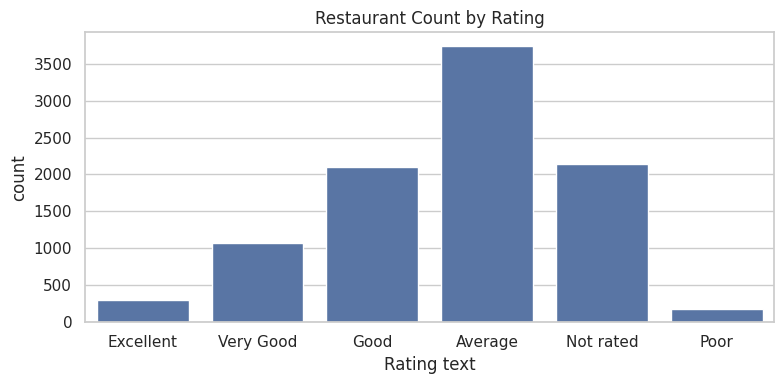

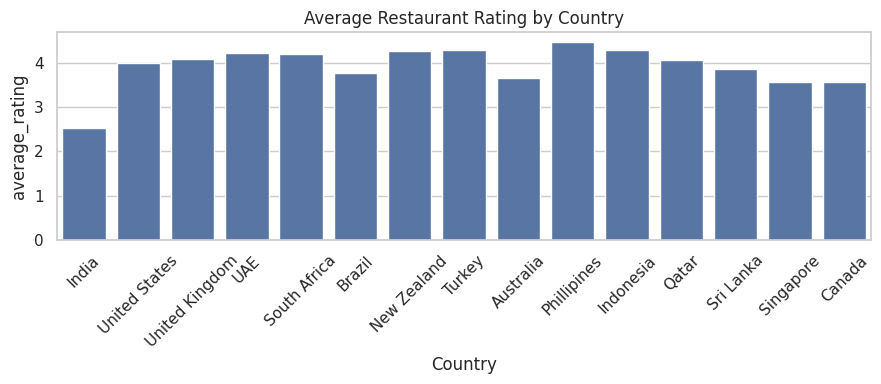

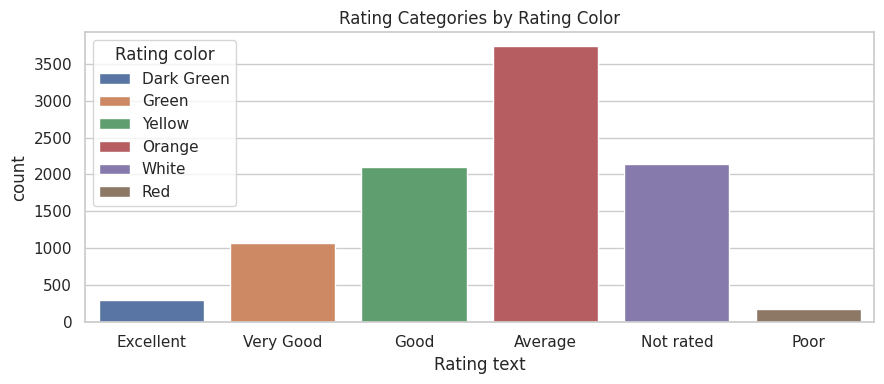

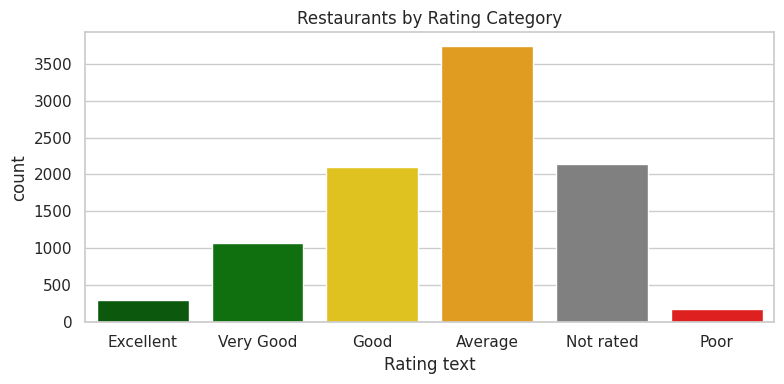

In [ ]:
# ------------------------------------------------------------
# 6. SEABORN: countplot() VS barplot()
# ------------------------------------------------------------

# countplot():
# Counts observations in each category automatically.
# Use it when the raw dataset contains one row per observation.

fig, ax = plt.subplots(figsize=(8, 4))

sns.countplot(
    data=zomato,
    x="Rating text",
    ax=ax
)

ax.set_title("Restaurant Count by Rating")

plt.tight_layout()
plt.show()

# barplot():
# Displays a numerical summary that you have already calculated.
# By default, seaborn estimates the mean for each category.

fig, ax = plt.subplots(figsize=(9, 4))

sns.barplot(
    data=country_summary.reset_index(),
    x="Country",
    y="average_rating",
    ax=ax
)

ax.set_title("Average Restaurant Rating by Country")
ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

# HUE:
# hue adds another categorical dimension using separate colours.
# Example: compare rating categories by rating colour.

fig, ax = plt.subplots(figsize=(9, 4))

sns.countplot(
    data=zomato,
    x="Rating text",
    hue="Rating color",
    ax=ax
)

ax.set_title("Rating Categories by Rating Color")

plt.tight_layout()
plt.show()

# PALETTE:
# Assign colours to categories.
# When using a palette, provide hue explicitly.
# If hue duplicates x, hide the redundant legend.

fig, ax = plt.subplots(figsize=(8, 4))

sns.countplot(
    data=zomato,
    x="Rating text",
    hue="Rating text",
    palette={
        "Not rated": "gray",
        "Poor": "red",
        "Average": "orange",
        "Good": "gold",
        "Very Good": "green",
        "Excellent": "darkgreen"
    },
    legend=False,
    ax=ax
)

ax.set_title("Restaurants by Rating Category")

plt.tight_layout()
plt.show()

# IMPORTANT:
# countplot = counts observations.
# barplot = summarizes a numerical variable.
# barplot() uses mean by default, with confidence intervals.
# Use errorbar=None when uncertainty intervals are not needed.
#
# Modern seaborn requires keyword arguments:
# sns.barplot(data=df, x="category", y="value")
# Old positional calls like sns.barplot("x", "y", data=df)
# can raise TypeError.



          Age    Fare
count  714.00  891.00
mean    29.70   32.20
std     14.53   49.69
min      0.42    0.00
25%     20.12    7.91
50%     28.00   14.45
75%     38.00   31.00
max     80.00  512.33


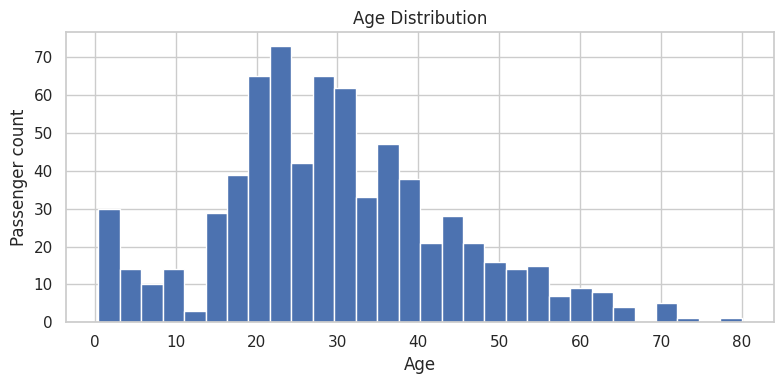

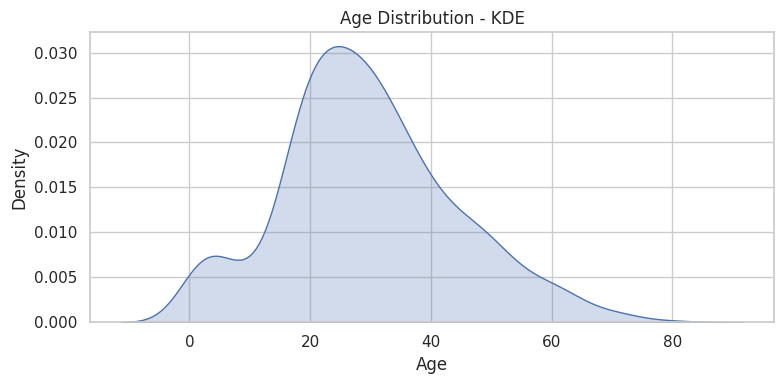

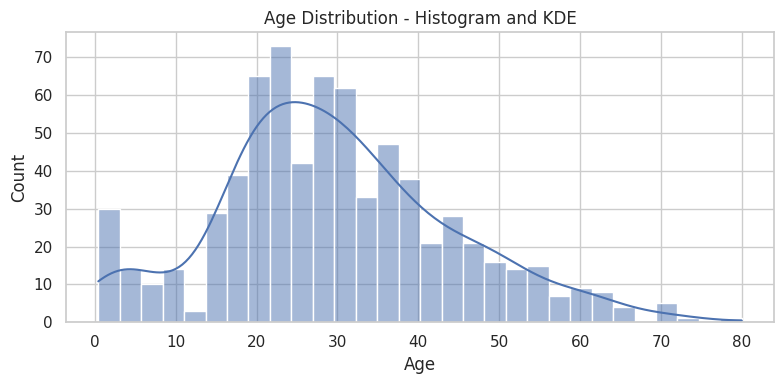

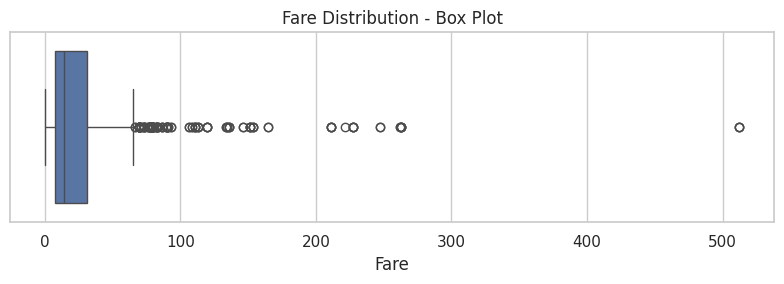

0.25     7.9104
0.50    14.4542
0.75    31.0000
Name: Fare, dtype: float64
Age mean: 29.69911764705882
Age median: 28.0
Fare mean: 32.204207968574636
Fare median: 14.4542


In [ ]:
# ------------------------------------------------------------
# 7. NUMERICAL DISTRIBUTIONS: HISTOGRAM, KDE AND BOX PLOT
# ------------------------------------------------------------

# A categorical column is usually explored using value_counts.
# A numerical column needs a distribution plot.

# Load numerical columns from Titanic.
age_fare = titanic[["Age", "Fare"]]

# Summary statistics.
print(age_fare.describe().round(2))

# HISTOGRAM:
# Divides values into bins and counts observations in each bin.
# Useful for understanding frequency and distribution shape.

fig, ax = plt.subplots(figsize=(8, 4))

titanic["Age"].hist(bins=30, ax=ax)

ax.set_xlabel("Age")
ax.set_ylabel("Passenger count")
ax.set_title("Age Distribution")

plt.tight_layout()
plt.show()

# KDE:
# Kernel Density Estimation produces a smoothed distribution curve.
# It helps visualize the overall shape of a numerical variable.

fig, ax = plt.subplots(figsize=(8, 4))

sns.kdeplot(
    data=titanic,
    x="Age",
    fill=True,
    ax=ax
)

ax.set_title("Age Distribution - KDE")

plt.tight_layout()
plt.show()

# HISTOGRAM + KDE:
fig, ax = plt.subplots(figsize=(8, 4))

sns.histplot(
    data=titanic,
    x="Age",
    bins=30,
    kde=True,
    ax=ax
)

ax.set_title("Age Distribution - Histogram and KDE")

plt.tight_layout()
plt.show()

# BOX PLOT:
# Displays median, Q1, Q3, whiskers and potential outliers.
# IQR = Q3 - Q1.
# Default whiskers extend to the most extreme observations
# within 1.5 * IQR from the quartiles.

fig, ax = plt.subplots(figsize=(8, 3))

sns.boxplot(
    data=titanic,
    x="Fare",
    ax=ax
)

ax.set_title("Fare Distribution - Box Plot")

plt.tight_layout()
plt.show()

# Inspect the quartiles used in a box plot.
print(titanic["Fare"].quantile([0.25, 0.50, 0.75]))

# Compare mean and median to understand skewness.
print("Age mean:", titanic["Age"].mean())
print("Age median:", titanic["Age"].median())

print("Fare mean:", titanic["Fare"].mean())
print("Fare median:", titanic["Fare"].median())

# INTERPRETATION:
# Mean > median often indicates right skew.
# Mean < median often indicates left skew.
# Mean approximately equal to median may indicate symmetry,
# but this alone does not prove a normal distribution.

# IMPORTANT:
# KDE is a smoothed estimate, not the actual observation count.
# Its shape depends on bandwidth.
# Missing values are excluded from these plots.
# A box plot marks potential outliers, not necessarily errors.



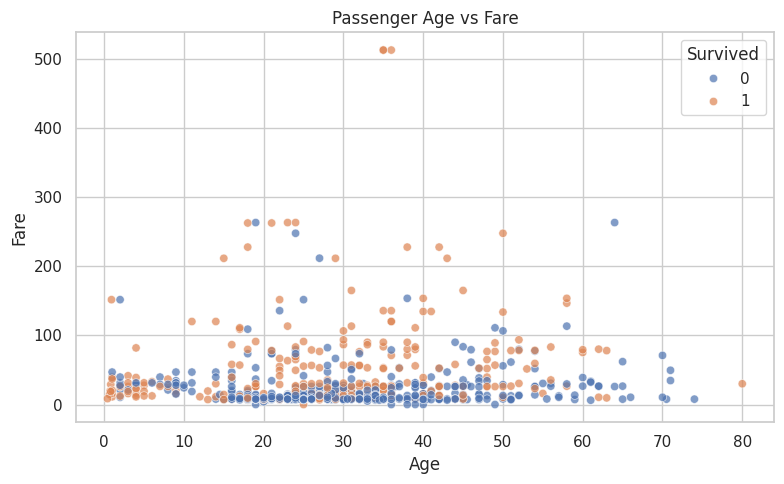

             PassengerId  Survived  Pclass   Age  SibSp  Parch  Fare
PassengerId         1.00     -0.01   -0.04  0.04  -0.06  -0.00  0.01
Survived           -0.01      1.00   -0.34 -0.08  -0.04   0.08  0.26
Pclass             -0.04     -0.34    1.00 -0.37   0.08   0.02 -0.55
Age                 0.04     -0.08   -0.37  1.00  -0.31  -0.19  0.10
SibSp              -0.06     -0.04    0.08 -0.31   1.00   0.41  0.16
Parch              -0.00      0.08    0.02 -0.19   0.41   1.00  0.22
Fare                0.01      0.26   -0.55  0.10   0.16   0.22  1.00
Age-Fare correlation: 0.0960666917690389


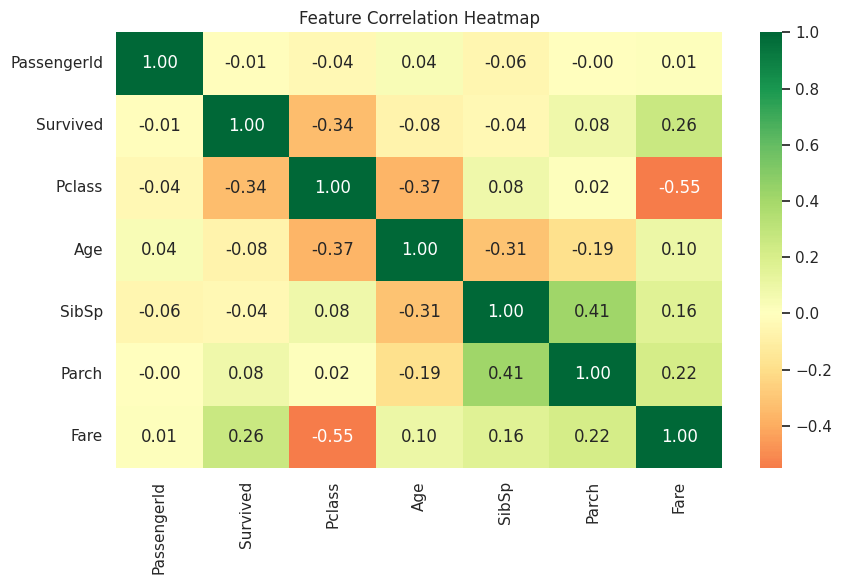

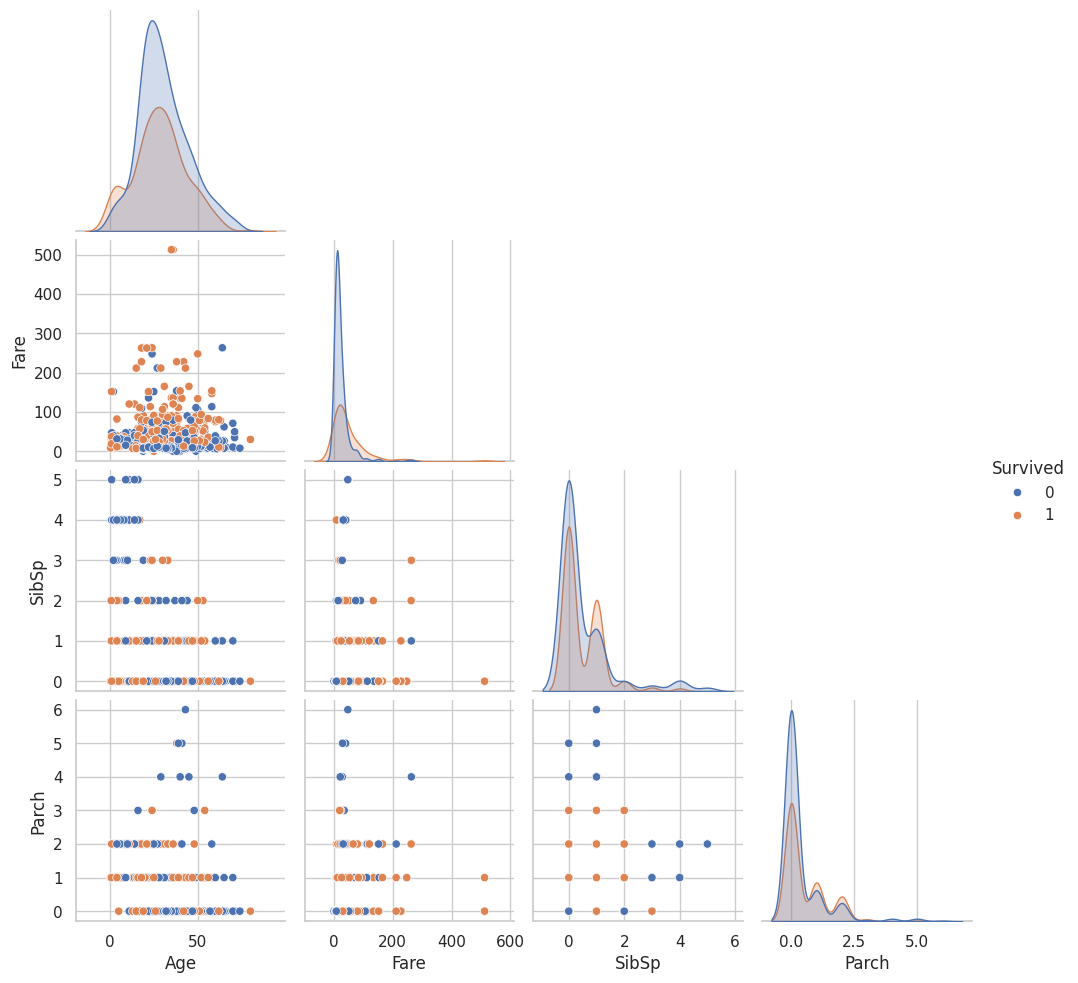

Spearman correlation:
             PassengerId  Survived  Pclass   Age  SibSp  Parch  Fare
PassengerId         1.00     -0.01   -0.03  0.04  -0.06   0.00 -0.01
Survived           -0.01      1.00   -0.34 -0.05   0.09   0.14  0.32
Pclass             -0.03     -0.34    1.00 -0.36  -0.04  -0.02 -0.69
Age                 0.04     -0.05   -0.36  1.00  -0.18  -0.25  0.14
SibSp              -0.06      0.09   -0.04 -0.18   1.00   0.45  0.45
Parch               0.00      0.14   -0.02 -0.25   0.45   1.00  0.41
Fare               -0.01      0.32   -0.69  0.14   0.45   0.41  1.00


In [ ]:


# ------------------------------------------------------------
# 8. RELATIONSHIPS BETWEEN FEATURES
# ------------------------------------------------------------

# One numerical feature:
# Distribution plots show how values are spread.

# Two numerical features:
# Scatter plots help identify relationships.

# Question:
# Do older passengers tend to pay higher fares?

fig, ax = plt.subplots(figsize=(8, 5))

sns.scatterplot(
    data=titanic,
    x="Age",
    y="Fare",
    hue="Survived",
    alpha=0.7,
    ax=ax
)

ax.set_title("Passenger Age vs Fare")

plt.tight_layout()
plt.show()

# CORRELATION:
# Pearson correlation measures linear association.
# Values range from -1 to +1.
# +1 = perfect positive linear relationship.
# -1 = perfect negative linear relationship.
#  0 = no linear correlation.

# numeric_only=True prevents text columns from causing errors
# in modern pandas versions.
correlation = titanic.corr(numeric_only=True)

print(correlation.round(2))

# Correlation between two specific features.
print(
    "Age-Fare correlation:",
    titanic["Age"].corr(titanic["Fare"])
)

# HEATMAP:
# Displays correlation coefficients between numerical columns.

fig, ax = plt.subplots(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    center=0,
    ax=ax
)

ax.set_title("Feature Correlation Heatmap")

plt.tight_layout()
plt.show()

# PAIRPLOT:
# Displays scatter plots for every pair of selected features
# and distribution plots along the diagonal.

# Use a small set of numerical columns.
# Plotting every feature can become computationally expensive.
sns.pairplot(
    titanic[["Age", "Fare", "SibSp", "Parch", "Survived"]].dropna(),
    hue="Survived",
    corner=True
)

plt.show()

# SPEARMAN CORRELATION:
# Measures monotonic association using ranks.
# Useful when the relationship is monotonic but not linear,
# or when Pearson correlation is sensitive to extreme values.

spearman = titanic.corr(
    method="spearman",
    numeric_only=True
)

print("Spearman correlation:")
print(spearman.round(2))

# IMPORTANT:
# Correlation does not establish causation.
# Pearson measures linear relationships, not every possible pattern.
# A near-zero Pearson correlation can still hide a nonlinear
# relationship.
# Pair plots and scatter plots help reveal such patterns.




In [ ]:

# ------------------------------------------------------------
# 9. FINAL: QUICK EDA VISUALIZATION CHECKLIST
# ------------------------------------------------------------

# CATEGORICAL COLUMN:
# value_counts() -> frequency
# countplot()    -> visual frequency
# barplot()      -> numerical summary by category
# pie()          -> part-to-whole for a few categories

# NUMERICAL COLUMN:
# histplot()     -> distribution and frequency
# kdeplot()      -> smoothed distribution
# boxplot()      -> quartiles and potential outliers

# MULTIPLE FEATURES:
# groupby()      -> summaries across groups
# scatterplot()  -> relationship between two variables
# pairplot()     -> multiple pairwise relationships
# corr()         -> numerical linear/monotonic association

# FINAL RULE:
# Every chart should answer a question.
# Every chart should have an observation.
# Every observation should be supported by the data.

In [ ]:
# ============================================================
# GROUP 04: DATA CLEANING AND FEATURE ENGINEERING
# Lessons 18-39 | pandas 3.0 | scikit-learn 1.9
# ============================================================


# ------------------------------------------------------------
# 1. SETUP AND DATASET
# ------------------------------------------------------------


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder,
    OrdinalEncoder,
    LabelEncoder,
    TargetEncoder
)

sns.set_theme(style="whitegrid")

# Load Titanic dataset.
URL = (
    "https://raw.githubusercontent.com/krishnaik06/"
    "Feature-Engineering-Live-sessions/master/titanic.csv"
)

df = pd.read_csv(URL)

print(df.shape)  # 891 rows x 12 columns


# ============================================================
# PART A: MISSING VALUE IMPUTATION
# ============================================================


# ------------------------------------------------------------
# 2. WHY VALUES GO MISSING: MCAR, MAR AND MNAR
# ------------------------------------------------------------

# MCAR: Missing Completely At Random.
# Missingness has no relationship with observed or missing data.
# Example: a sensor randomly fails to record a measurement.

# MAR: Missing At Random.
# Missingness depends on another observed variable.
# Example: age is more frequently missing for a particular class.

# MNAR: Missing Not At Random.
# Missingness depends on the missing value itself or the target.
# Example: higher earners are less likely to report their income.

# Check missing-value counts and percentages.
print(df.isnull().sum())
print((df.isnull().mean() * 100).round(2))

# Create an indicator to investigate whether missingness
# is associated with the target.
df["Cabin_missing"] = df["Cabin"].isna().astype(int)

# Compare survival rates for passengers with and without a cabin.
print(
    df.groupby("Cabin_missing")["Survived"]
    .agg(["mean", "count"])
)

# A difference suggests that missingness carries information.
# It does NOT prove causality or establish MNAR by itself.
# Domain knowledge is required to distinguish MAR from MNAR.

# Inspect rows with missing Embarked values.
print(
    df.loc[
        df["Embarked"].isna(),
        ["Name", "Pclass", "Fare", "Cabin", "Ticket"]
    ]
)

# dropna() without subset removes rows missing ANY column.
# This can destroy a large portion of the dataset.
print("Rows after blanket dropna:", len(df.dropna()))

# Drop rows only when the specific missing column is relevant.
print("Rows after dropping missing Embarked:",
      len(df.dropna(subset=["Embarked"])))



Mean: 29.69911764705882
Median: 28.0
Original std: 14.526497332334044
Mean-imputed std: 13.002015226002884
Median-imputed std: 13.019696550973194
Age 28 before: 25
Age 28 after : 202


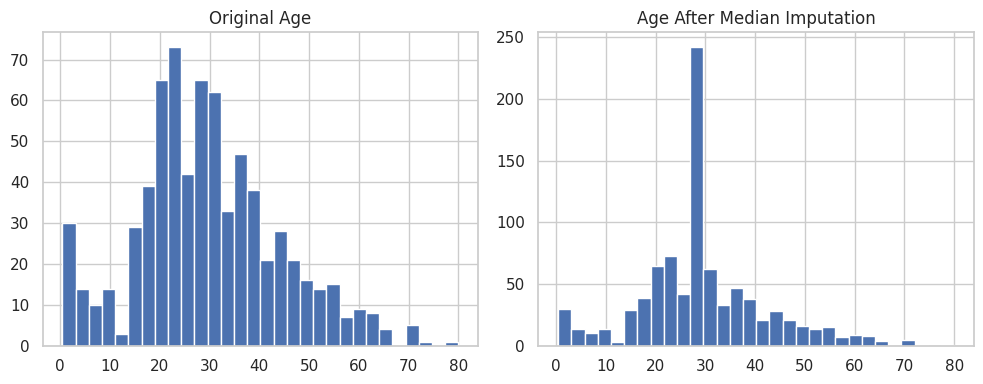

In [ ]:

# ------------------------------------------------------------
# 3. MEAN AND MEDIAN IMPUTATION
# ------------------------------------------------------------

# Mean: suitable for approximately symmetric numerical features.
# Median: more robust when a feature is skewed or has outliers.

age = df["Age"]

print("Mean:", age.mean())
print("Median:", age.median())

# Create separate versions to compare the effect.
df["Age_mean"] = age.fillna(age.mean())
df["Age_median"] = age.fillna(age.median())

# Imputation fills gaps but reduces the natural variation.
print("Original std:", age.std())
print("Mean-imputed std:", df["Age_mean"].std())
print("Median-imputed std:", df["Age_median"].std())

# Check how the number of observations at the median changes.
print("Age 28 before:", (age == 28).sum())
print("Age 28 after :", (df["Age_median"] == 28).sum())

# Visualize the effect of median imputation.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

age.hist(bins=30, ax=axes[0])
axes[0].set_title("Original Age")

df["Age_median"].hist(bins=30, ax=axes[1])
axes[1].set_title("Age After Median Imputation")

plt.tight_layout()
plt.show()

# IMPORTANT:
# Mean imputation is sensitive to outliers.
# Median imputation is more robust.
# Both can distort distributions and weaken feature relationships.
# Add a missing indicator if the fact that a value was missing matters.



In [ ]:
# ------------------------------------------------------------
# 4. RANDOM SAMPLE IMPUTATION
# ------------------------------------------------------------

# Replace missing values with randomly sampled observed values.
# This approximately preserves the original distribution
# and variation better than filling every gap with one constant.

age = df["Age"].copy()

# Find positions of missing and observed values.
missing_mask = age.isna()
observed_values = age.dropna()

# Sample from the observed distribution.
# random_state makes the result reproducible.
random_values = observed_values.sample(
    n=missing_mask.sum(),
    replace=True,
    random_state=42
)

# Fill missing positions with sampled values.
age_random = age.copy()
age_random.loc[missing_mask] = random_values.to_numpy()

print("Missing after imputation:", age_random.isna().sum())
print("Original std:", age.std())
print("Random-imputed std:", age_random.std())

# IMPORTANT:
# Random sample imputation preserves the marginal distribution
# approximately, but it does not preserve relationships between
# the missing feature and other features.
# Use a fixed random seed for reproducibility.
# Sample only from observed training values in an ML workflow.



Missing after imputation: 0
Original std: 14.526497332334044
Random-imputed std: 14.633756217184047


In [ ]:
# ------------------------------------------------------------
# 5. MISSING VALUE INDICATOR
# ------------------------------------------------------------

# A missing indicator records whether a value was originally absent.
# 1 = missing; 0 = observed.

df["Age_missing"] = df["Age"].isna().astype(int)

# Fill Age separately.
df["Age_with_indicator"] = df["Age"].fillna(
    df["Age"].median()
)

# Compare the target across missing and observed groups.
print(
    df.groupby("Age_missing")["Survived"]
    .agg(["mean", "count"])
)

# The indicator preserves missingness information that
# mean/median imputation would otherwise remove.

# Useful when missingness is informative (often MAR or MNAR).
# It does not fix a poor imputation strategy by itself.



                 mean  count
Age_missing                 
0            0.406162    714
1            0.293785    177


In [ ]:

# ------------------------------------------------------------
# 6. END-OF-DISTRIBUTION IMPUTATION
# ------------------------------------------------------------

# Fill missing values with a value far into the distribution tail.
# A common choice is mean + 3 standard deviations.

mean = df["Age"].mean()
std = df["Age"].std()

upper_fence = mean + 3 * std
lower_fence = mean - 3 * std

print("Lower:", lower_fence)
print("Upper:", upper_fence)

df["Age_end"] = df["Age"].fillna(upper_fence)

# Missing observations now have an extreme value.
print("Missing:", df["Age_end"].isna().sum())
print("Values above upper fence:",
      (df["Age_end"] > upper_fence).sum())

# IMPORTANT:
# The 3-sigma rule assumes a roughly normal distribution.
# It is a convention, not a universal rule.
# For Age, the lower fence may be negative and therefore
# physically impossible.
# This method deliberately creates extreme observations.
# It can distort subsequent outlier checks and scaling.



Lower: -13.88037434994331
Upper: 73.27860964406095
Missing: 0
Values above upper fence: 2


In [ ]:
# ------------------------------------------------------------
# 7. ARBITRARY VALUE IMPUTATION
# ------------------------------------------------------------

# Replace missing values with a fixed value chosen in advance.
# Example: -999, 0 or another value outside the valid range.

df["Age_arbitrary"] = df["Age"].fillna(-999)

print(df["Age_arbitrary"].value_counts().head())

# The selected value should be distinguishable from valid values.
# For example, -999 is invalid for age and can act as a missing flag.

# LIMITATION:
# Extreme values can distort mean, standard deviation and scaling.
# Some algorithms may treat the arbitrary value as a real measurement.


# ------------------------------------------------------------
# 8. FREQUENT CATEGORY IMPUTATION
# ------------------------------------------------------------

# For categorical features, replace missing values with the mode.
# Mode = most frequently occurring category.

print(df["Embarked"].value_counts())

most_frequent = df["Embarked"].mode()[0]

print("Most frequent category:", most_frequent)

df["Embarked_mode"] = df["Embarked"].fillna(most_frequent)

# Check that missing values are removed.
print(df["Embarked_mode"].isna().sum())

# IMPORTANT:
# Mode imputation can increase the dominance of the most frequent
# category and distort category proportions.
# It works best when missingness is limited and the mode is meaningful.


# ------------------------------------------------------------
# 9. MISSING AS ITS OWN CATEGORY
# ------------------------------------------------------------

# Instead of guessing a category, create a separate Missing label.
# Useful when missingness itself may carry information.

df["Cabin_category"] = df["Cabin"].fillna("Missing")

print(df["Cabin_category"].value_counts().head())

# A cabin number can contain several pieces of information.
# The first character represents the deck.
df["Deck"] = df["Cabin_category"].str[0]

print(df["Deck"].value_counts())

# IMPORTANT:
# Do not replace missing categories with an existing category
# unless you have a reason to assume they are equivalent.
# A dedicated category preserves the distinction.



In [ ]:

# ------------------------------------------------------------
# 10. SIMPLEIMPUTER IN SCIKIT-LEARN
# ------------------------------------------------------------

# SimpleImputer applies a consistent imputation strategy
# and can be fitted on training data and applied to test data.

numeric_data = df[["Age", "Fare"]].copy()

# Mean, median and most_frequent are supported strategies.
median_imputer = SimpleImputer(strategy="median")

numeric_imputed = median_imputer.fit_transform(numeric_data)

print("Imputer statistics:", median_imputer.statistics_)
print("Output shape:", numeric_imputed.shape)

# Most frequent value for categorical data.
categorical_data = df[["Embarked"]].copy()

mode_imputer = SimpleImputer(strategy="most_frequent")

categorical_imputed = mode_imputer.fit_transform(categorical_data)

# Constant strategy fills every missing value with a fixed value.
constant_imputer = SimpleImputer(
    strategy="constant",
    fill_value="Missing"
)

cabin_imputed = constant_imputer.fit_transform(
    df[["Cabin_category"]]
)

# add_indicator=True adds binary columns identifying missing values.
indicator_imputer = SimpleImputer(
    strategy="median",
    add_indicator=True
)

age_with_flag = indicator_imputer.fit_transform(
    df[["Age"]]
)

print("Age + indicator shape:", age_with_flag.shape)

# IMPORTANT:
# fit() learns statistics; transform() applies them.
# Never fit an imputer on the complete dataset before splitting.
# SimpleImputer can be placed inside a Pipeline and ColumnTransformer.



In [ ]:
# ============================================================
# PART B: OUTLIER DETECTION AND TREATMENT
# ============================================================


# ------------------------------------------------------------
# 11. UNDERSTANDING OUTLIERS
# ------------------------------------------------------------

# An outlier is a value far from the typical observations.
# It may be:
# 1. A data error: age = 300.
# 2. A rare but valid observation: Titanic fare = 512.
# 3. A different population: wholesale vs retail customers.
# 4. Noise: an ordinary but unusual measurement.

# Use controlled data to demonstrate outlier effects.
readings = [
    11, 10, 12, 14, 12, 15, 14, 13, 15, 102, 12, 14, 17, 19,
    107, 10, 13, 12, 14, 12, 108, 12, 11, 14, 13, 15, 10,
    15, 12, 10, 14, 13, 15, 10
]

values = np.array(readings)

# Compare mean, median and standard deviation.
print("Original:")
print("Mean:", values.mean())
print("Median:", np.median(values))
print("Std:", values.std())

# Remove the three extreme values for comparison only.
clean = values[values < 50]

print("\nWithout extreme values:")
print("Mean:", clean.mean())
print("Median:", np.median(clean))
print("Std:", clean.std())

# Outliers can strongly affect:
# Linear regression, logistic regression, K-Means, PCA,
# neural networks and standardisation.
#
# Tree-based models are generally less sensitive to extreme
# numerical magnitudes because they split based on thresholds.
# However, outliers can still affect tree structure and data quality.


# ------------------------------------------------------------
# 12. Z-SCORE METHOD
# ------------------------------------------------------------

# Z-score measures how many standard deviations a value
# lies from the mean.
#
# z = (x - mean) / standard deviation
#
# A common rule flags values with |z| > 3.

mean = values.mean()

# NumPy uses population standard deviation by default (ddof=0).
std = values.std(ddof=0)

z_scores = (values - mean) / std

outlier_mask = np.abs(z_scores) > 3

print("Z-score outliers:", values[outlier_mask])

# SciPy alternative.
z_scipy = stats.zscore(values)

print("SciPy outliers:", values[np.abs(z_scipy) > 3])

# pandas Series.std() uses ddof=1 by default.
# NumPy uses ddof=0.
# Choose the convention consistently.

# IMPORTANT:
# Z-score works best for approximately normal distributions.
# Extreme values influence the mean and standard deviation,
# which can make outliers harder to detect.


# ------------------------------------------------------------
# 13. IQR METHOD
# ------------------------------------------------------------

# IQR = Q3 - Q1
# Lower fence = Q1 - 1.5 * IQR
# Upper fence = Q3 + 1.5 * IQR

Q1 = np.percentile(values, 25)
Q3 = np.percentile(values, 75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower fence:", lower)
print("Upper fence:", upper)

iqr_mask = (values < lower) | (values > upper)

print("IQR outliers:", values[iqr_mask])

# IQR is more robust to extreme values than Z-score.
# It does not require a normal distribution.
# It is useful for skewed numerical distributions too.


# ------------------------------------------------------------
# 14. TREATING OUTLIERS: KEEP, CAP OR DROP
# ------------------------------------------------------------

# OPTION 1: Keep the outliers.
# Appropriate when they are valid observations and meaningful.

# OPTION 2: Capping / Winsorization.
# Replace values outside the fences with the boundary values.

capped = np.clip(values, lower, upper)

print("Original max:", values.max())
print("Capped max:", capped.max())

# Pandas alternative:
sensor = pd.Series(values)

sensor_capped = sensor.clip(
    lower=lower,
    upper=upper
)

# OPTION 3: Remove observations outside the fences.
# Use only when the observations are invalid or removal is justified.

sensor_dropped = sensor[
    (sensor >= lower) & (sensor <= upper)
]

print("Original rows:", len(sensor))
print("Rows after dropping:", len(sensor_dropped))

# OPTION 4: Winsorization using SciPy.
# Limits specify the fraction clipped from each tail.
winsorized = stats.mstats.winsorize(
    values,
    limits=[0.05, 0.05]
)

print("Winsorized:", np.asarray(winsorized))

# IMPORTANT:
# Do not remove an observation merely because it is flagged.
# Understand whether it is an error, a rare truth or another group.
# Capping preserves row count but changes extreme values.
# Dropping reduces the dataset and can introduce selection bias.
# Learn capping thresholds from training data only.


(891, 12)
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
PassengerId     0.00
Survived        0.00
Pclass          0.00
Name            0.00
Sex             0.00
Age            19.87
SibSp           0.00
Parch           0.00
Ticket          0.00
Fare            0.00
Cabin          77.10
Embarked        0.22
dtype: float64
                   mean  count
Cabin_missing                 
0              0.666667    204
1              0.299854    687
                                          Name  Pclass  Fare Cabin  Ticket
61                         Icard, Miss. Amelie       1  80.0   B28  113572
829  Stone, Mrs. George Nelson (Martha Evelyn)       1  80.0   B28  113572
Rows after blanket dropna: 183
Rows after dropping missing Embarked: 889
Mean: 29.69911764705882
Median: 28.0
Original std: 14.526497

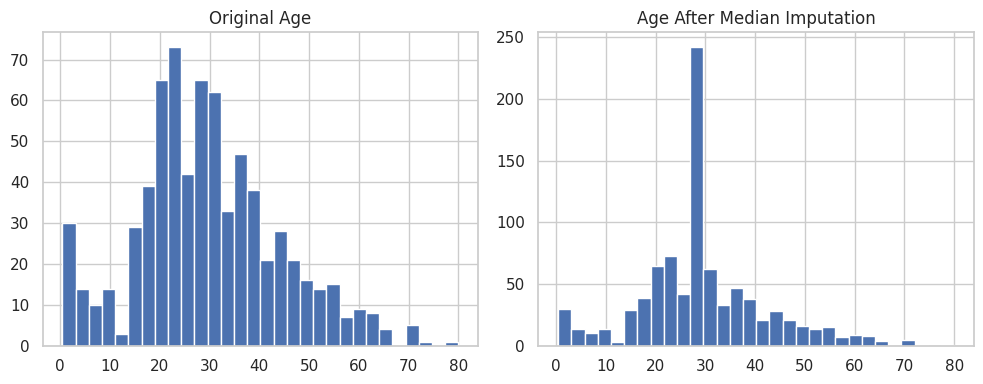

Missing after imputation: 0
Original std: 14.526497332334044
Random-imputed std: 14.633756217184047
                 mean  count
Age_missing                 
0            0.406162    714
1            0.293785    177
Lower: -13.88037434994331
Upper: 73.27860964406095
Missing: 0
Values above upper fence: 2
Age_arbitrary
-999.0    177
 24.0      30
 22.0      27
 18.0      26
 28.0      25
Name: count, dtype: int64
Embarked
S    644
C    168
Q     77
Name: count, dtype: int64
Most frequent category: S
0
Cabin_category
Missing        687
G6               4
C23 C25 C27      4
B96 B98          4
F2               3
Name: count, dtype: int64
Deck
M    687
C     59
B     47
D     33
E     32
A     15
F     13
G      4
T      1
Name: count, dtype: int64
Imputer statistics: [28.     14.4542]
Output shape: (891, 2)
Age + indicator shape: (891, 2)
Original:
Mean: 21.176470588235293
Median: 13.0
Std: 26.37230118696876

Without extreme values:
Mean: 13.0
Median: 13.0
Std: 2.109884571066817
Z-score ou

In [ ]:




# ============================================================
# PART C: CATEGORICAL FEATURE ENCODING
# ============================================================


# ------------------------------------------------------------
# 15. NOMINAL VS ORDINAL FEATURES
# ------------------------------------------------------------

# NOMINAL:
# Categories have no natural ranking.
# Examples: City, Gender, Colour, Country.
# Use One-Hot, Frequency or other suitable encodings.

# ORDINAL:
# Categories have a meaningful order.
# Examples: Low < Medium < High.
# Use an explicitly defined ordinal mapping.

example = pd.DataFrame({
    "City": ["Mumbai", "Delhi", "Pune", "Mumbai"],
    "Education": ["Graduate", "Postgraduate", "PhD", "Graduate"],
    "Satisfaction": ["Low", "Medium", "High", "Medium"]
})

# Nominal categories: no artificial numerical ordering.
print(example["City"].unique())

# Ordinal categories: define the actual order.
satisfaction_order = ["Low", "Medium", "High"]

example["Satisfaction_code"] = (
    example["Satisfaction"]
    .map({
        "Low": 1,
        "Medium": 2,
        "High": 3
    })
)

print(example)


# ------------------------------------------------------------
# 16. ONE-HOT ENCODING
# ------------------------------------------------------------

# Create one binary column per category.
# Useful for nominal features without a natural order.

city_dummies = pd.get_dummies(
    example["City"],
    dtype=int
)

print(city_dummies)

# drop_first=True removes one category to avoid perfect
# multicollinearity in models with an intercept.
city_dummies_reduced = pd.get_dummies(
    example["City"],
    drop_first=True,
    dtype=int
)

print(city_dummies_reduced)

# IMPORTANT:
# pandas 3.0 returns boolean columns by default if dtype is omitted.
# Use dtype=int when you explicitly need 0 and 1.

# scikit-learn alternative.
# handle_unknown='ignore' prevents errors for unseen categories.
ohe = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False,
    dtype=int
)

city_encoded = ohe.fit_transform(example[["City"]])

print(ohe.get_feature_names_out(["City"]))
print(city_encoded)

# fit learns the available categories.
# transform applies the learned encoding.
# Unknown categories become all-zero columns with handle_unknown="ignore".


# ------------------------------------------------------------
# 17. ONE-HOT ENCODING WITH MANY CATEGORIES
# ------------------------------------------------------------

# High-cardinality features can create hundreds or thousands
# of new columns.
# Example: cities, postcodes, product IDs.

cities = pd.Series([
    "Mumbai", "Delhi", "Pune", "Mumbai",
    "Bangalore", "Delhi", "Chennai", "Mumbai",
    "Hyderabad", "Pune", "Kolkata", "Mumbai"
])

# Identify the top 3 most frequent categories.
top_categories = cities.value_counts().head(3).index

# Keep the top categories and group the rest into Others.
cities_grouped = cities.where(
    cities.isin(top_categories),
    "Others"
)

print(cities_grouped.value_counts())

# Encode the reduced categories.
top_dummies = pd.get_dummies(
    cities_grouped,
    dtype=int
)

print(top_dummies)

# For production, learn the top categories on training data only.
# Unseen and rare test categories should map to Others.
# High cardinality can cause dimensionality and sparsity problems.


# ------------------------------------------------------------
# 18. ORDINAL ENCODING
# ------------------------------------------------------------

# Use OrdinalEncoder for input features with a known order.

education_order = [
    ["High School", "Graduate", "Postgraduate", "PhD"]
]

education = pd.DataFrame({
    "Education": [
        "Graduate",
        "PhD",
        "High School",
        "Postgraduate"
    ]
})

ordinal_encoder = OrdinalEncoder(
    categories=education_order,
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

education["Education_code"] = ordinal_encoder.fit_transform(
    education[["Education"]]
)

print(education)

# IMPORTANT:
# Never use alphabetical ordering when a domain-specific
# order exists.
# Ordinal encoding introduces numerical ordering.
# Use it only when that ordering is meaningful.


# ------------------------------------------------------------
# 19. LABEL ENCODING
# ------------------------------------------------------------

# LabelEncoder converts target labels into integers.
# It is intended for y, not normally for nominal X features.

y = pd.Series(["No", "Yes", "No", "Yes", "Yes"])

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Classes:", label_encoder.classes_)
print("Encoded:", y_encoded)

# Decode the numbers back into original labels.
print(label_encoder.inverse_transform(y_encoded))

# IMPORTANT:
# LabelEncoder sorts classes alphabetically by default.
# 0 and 1 are just identifiers; they do not indicate
# a natural order between nominal categories.
# For input features, use OneHotEncoder or another suitable encoder.


# ------------------------------------------------------------
# 20. COUNT AND FREQUENCY ENCODING
# ------------------------------------------------------------

# Count encoding replaces a category with its frequency count.
# Frequency encoding replaces it with its relative frequency.

city_counts = cities.value_counts()

city_count_encoded = cities.map(city_counts)

city_frequency_encoded = cities.map(
    cities.value_counts(normalize=True)
)

print(pd.DataFrame({
    "City": cities,
    "Count": city_count_encoded,
    "Frequency": city_frequency_encoded
}))

# COUNT:
# Mumbai -> 4
# Delhi  -> 2

# FREQUENCY:
# Mumbai -> 4 / 12
# Delhi  -> 2 / 12

# IMPORTANT:
# Count encoding reduces the number of columns.
# Different categories may share the same count.
# It can lose category identity.
# Learn the mapping on training data only.

# Example: fit mapping on training rows and apply to test rows.
city_train, city_test = train_test_split(
    cities,
    test_size=0.25,
    random_state=42
)

count_map = city_train.value_counts()

test_count_encoded = city_test.map(count_map).fillna(0)

print("Training map:", count_map.to_dict())
print("Test encoding:", test_count_encoded.tolist())


# ------------------------------------------------------------
# 21. TARGET-GUIDED ORDINAL ENCODING
# ------------------------------------------------------------

# Order categories according to their average target value.
# Example: categories ordered by survival rate.

titanic = df[["Survived", "Cabin", "Pclass", "Age"]].copy()

# Extract deck from cabin.
# Missing cabins become their own category.
titanic["Deck"] = titanic["Cabin"].fillna("Missing").str[0]

X = titanic[["Deck", "Pclass", "Age"]]
y = titanic["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Calculate survival rate by deck using training data only.
deck_order = (
    y_train.groupby(X_train["Deck"])
    .mean()
    .sort_values()
    .index
)

# Lowest survival rate = 0, highest = largest code.
deck_mapping = {
    category: index
    for index, category in enumerate(deck_order)
}

print("Deck mapping:", deck_mapping)

# Apply the same mapping to training and test data.
X_train["Deck_encoded"] = X_train["Deck"].map(deck_mapping)

X_test["Deck_encoded"] = (
    X_test["Deck"].map(deck_mapping).fillna(-1)
)

# -1 indicates a category not observed during training.

# IMPORTANT:
# Never calculate category-target relationships on the complete
# dataset. That would leak test-target information.
# Rare categories can have unreliable survival-rate estimates.


# ------------------------------------------------------------
# 22. MEAN ENCODING / TARGET ENCODING
# ------------------------------------------------------------

# Replace each category with its average target value.
# Similar to target-guided ordinal encoding, but the encoded
# value is the target mean rather than a rank.

# sklearn TargetEncoder uses smoothing and cross-fitting
# during fit_transform to reduce overfitting.

target_encoder = TargetEncoder(
    target_type="binary",
    smooth="auto",
    cv=5,
    random_state=42
)

# Cross-fitted training encoding.
# Each training row is encoded using folds that exclude that row.
deck_train_encoded = target_encoder.fit_transform(
    X_train[["Deck"]],
    y_train
)

# Test data uses the mapping learned from the training data.
deck_test_encoded = target_encoder.transform(
    X_test[["Deck"]]
)

print("Train encoding shape:", deck_train_encoded.shape)
print("Test encoding shape:", deck_test_encoded.shape)

# IMPORTANT:
# Mean encoding can overfit when categories have very few samples.
# Smoothing pulls unreliable category means toward the global mean.
# Cross-fitting prevents a row's own target from directly determining
# its training encoding.
# Do not use fit_transform on the full dataset before splitting.



In [ ]:

# ------------------------------------------------------------
# 23. HANDLING UNKNOWN CATEGORIES
# ------------------------------------------------------------

# A common problem:
# Training data contains Mumbai and Delhi.
# Test data contains Pune, which was never observed during training.

train_cities = pd.DataFrame({
    "City": ["Mumbai", "Delhi", "Mumbai", "Delhi"]
})

test_cities = pd.DataFrame({
    "City": ["Mumbai", "Pune"]
})

# Default OneHotEncoder raises an error for unseen categories.
# handle_unknown='ignore' allows the transformation to continue.

unknown_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False,
    dtype=int
)

train_encoded = unknown_encoder.fit_transform(train_cities)
test_encoded = unknown_encoder.transform(test_cities)

print("Known categories:", unknown_encoder.categories_)
print("Training:")
print(train_encoded)

print("Testing with unknown Pune:")
print(test_encoded)

# Pune receives all zeros because it has no learned category column.

# OrdinalEncoder alternative:
# Explicitly assign an unknown value.
unknown_ordinal = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

train_ordinal = unknown_ordinal.fit_transform(train_cities)
test_ordinal = unknown_ordinal.transform(test_cities)

print("Ordinal test encoding:", test_ordinal)

# IMPORTANT:
# Never refit an encoder on test data to make unknown categories
# disappear. That changes the feature space.
# Decide how unknown categories should be represented in advance.



In [ ]:

# ============================================================
# FINAL: FEATURE ENGINEERING CHECKLIST
# ============================================================

# MISSING VALUES:
# MCAR / MAR / MNAR -> understand why data is missing.
# Mean / Median     -> numerical features.
# Random Sample     -> preserve distribution approximately.
# Indicator        -> retain missingness information.
# End Distribution -> deliberately create an extreme category.
# Arbitrary Value   -> use a distinguishable fixed value.
# Mode              -> categorical features.
# Missing Category  -> preserve missingness as a label.
# SimpleImputer     -> reusable sklearn transformer.

# OUTLIERS:
# Z-score           -> mean and standard deviation.
# IQR               -> Q1, Q3 and 1.5 * IQR.
# Capping           -> retain rows, limit extreme values.
# Dropping          -> remove invalid observations.
# Keeping           -> retain genuine rare observations.

# CATEGORICAL:
# One-Hot           -> nominal categories.
# Ordinal           -> meaningful category order.
# LabelEncoder      -> target labels (y).
# Count/Frequency   -> high-cardinality features.
# Target-guided     -> rank categories by target relationship.
# Mean Encoding     -> category-level target mean.
# Unknown Handling  -> define behavior for unseen categories.

# MOST IMPORTANT:
# Split first.
# Learn imputation statistics, outlier thresholds and encoding
# mappings on training data only.
# Apply the learned transformations to test data.


In [ ]:

# ============================================================
# GROUP 05: SCALING, TRANSFORMATION, DATE FEATURES & IMBALANCE
# Lessons 40-56 | pandas 3.0 | scikit-learn 1.9
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    RobustScaler,
    PowerTransformer
)

from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.datasets import make_classification
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    recall_score
)

from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE

sns.set_theme(style="whitegrid")


# ============================================================
# PART A: SCALING AND TRANSFORMATION
# ============================================================


# ------------------------------------------------------------
# 2. WHY FEATURES NEED SCALING
# ------------------------------------------------------------

# Features often have different numerical ranges.
# Example: Age = 0-80, Fare = 0-512.
# Algorithms using distances or gradients can be affected
# when one feature has a much larger numerical scale.

# Euclidean distance between two observations:
# d = sqrt(sum((x1 - x2) ** 2))

# NumPy demonstration.
p = np.array([24.0, 54.0])
q = np.array([30.0, 70.0])

squared_gaps = (p - q) ** 2

distance = np.sqrt(squared_gaps.sum())

print("Squared gaps:", squared_gaps)
print("Euclidean distance:", distance)

# The second feature contributes:
print(
    "Feature 2 contribution:",
    f"{squared_gaps[1] / squared_gaps.sum():.1%}"
)

# Load Titanic data.
URL = (
    "https://raw.githubusercontent.com/krishnaik06/"
    "Feature-Engineering-Live-sessions/master/titanic.csv"
)

titanic = pd.read_csv(URL, usecols=["Age", "Fare"])

# Impute missing Age before scaling.
titanic["Age"] = titanic["Age"].fillna(
    titanic["Age"].median()
)

# Compare the squared distance contribution before scaling.
def distance_contribution(frame):
    gaps = (frame.iloc[0] - frame.iloc[1]) ** 2

    return (
        np.sqrt(gaps.sum()),
        gaps / gaps.sum()
    )

print("Before scaling:", distance_contribution(titanic))

# Divide each column by its maximum.
scaled = titanic / titanic.max()

print("After scaling:", distance_contribution(scaled))

# IMPORTANT:
# Distance-based algorithms:
# KNN, K-Means, hierarchical clustering.
#
# Gradient-based algorithms:
# Linear regression, logistic regression, neural networks.
#
# Generally do not require scaling:
# Decision trees, Random Forest, tree-based boosting models.
#
# Scaling does not automatically improve every model.
# It is not required just because features have different units.


# ------------------------------------------------------------
# 3. STANDARDISATION: StandardScaler
# ------------------------------------------------------------

# Standardisation:
# X_scaled = (X - mean) / standard deviation
#
# Result: mean approximately 0, standard deviation approximately 1.
# It does not restrict values to the range 0-1.

X = titanic[["Age", "Fare"]]

# Split before fitting the scaler.
X_train, X_test = train_test_split(
    X,
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()

# Learn mean and standard deviation from training data.
X_train_scaled = scaler.fit_transform(X_train)

# Apply the SAME learned values to test data.
X_test_scaled = scaler.transform(X_test)

print("Learned means:", scaler.mean_)
print("Learned scales:", scaler.scale_)

print("Training mean:", X_train_scaled.mean(axis=0))
print("Training std:", X_train_scaled.std(axis=0))

# NumPy alternative for manual standardisation.
train_mean = X_train.mean()
train_std = X_train.std(ddof=0)

X_train_numpy = (X_train - train_mean) / train_std
X_test_numpy = (X_test - train_mean) / train_std

# IMPORTANT:
# pandas std() defaults to ddof=1.
# StandardScaler uses population standard deviation (ddof=0).
# This explains small differences in manual calculations.

# Never call fit_transform() separately on test data.
# Test data must use the training mean and standard deviation.


# ------------------------------------------------------------
# 4. MIN-MAX SCALING: MinMaxScaler
# ------------------------------------------------------------

# Formula:
# X_scaled = (X - X_min) / (X_max - X_min)
#
# Default output range: 0 to 1.
# Useful when a bounded feature range is required.

minmax = MinMaxScaler()

X_train_minmax = minmax.fit_transform(X_train)
X_test_minmax = minmax.transform(X_test)

print("Training minimum:", X_train_minmax.min(axis=0))
print("Training maximum:", X_train_minmax.max(axis=0))

# NumPy alternative.
train_min = X_train.min()
train_max = X_train.max()

X_train_manual = (X_train - train_min) / (train_max - train_min)
X_test_manual = (X_test - train_min) / (train_max - train_min)

# IMPORTANT:
# An unseen test value can fall outside 0-1 if it is beyond
# the minimum or maximum observed during training.
# MinMaxScaler does not automatically clip test values.
#
# Outliers strongly influence the minimum and maximum.
# Use clip=True only when clipping is appropriate.


# ------------------------------------------------------------
# 5. ROBUST SCALING: RobustScaler
# ------------------------------------------------------------

# Formula:
# X_scaled = (X - median) / IQR
# IQR = Q3 - Q1
#
# Uses median and quartiles instead of mean and standard deviation.
# More robust to extreme values.

robust = RobustScaler()

X_train_robust = robust.fit_transform(X_train)
X_test_robust = robust.transform(X_test)

print("Robust center:", robust.center_)
print("Robust scale:", robust.scale_)

# NumPy / pandas alternative.
train_median = X_train.median()
train_iqr = X_train.quantile(0.75) - X_train.quantile(0.25)

X_train_robust_manual = (
    X_train - train_median
) / train_iqr

# IMPORTANT:
# RobustScaler reduces the influence of outliers.
# It does not remove outliers or make the distribution normal.
# Values are not restricted to any fixed range.


# ------------------------------------------------------------
# 6. COMPARE THE THREE SCALERS
# ------------------------------------------------------------

# Fit each scaler on the same training data.
scalers = {
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "RobustScaler": RobustScaler()
}

for name, transformer in scalers.items():
    transformed = transformer.fit_transform(X_train)

    print(f"\n{name}")
    print("Minimum:", transformed.min(axis=0).round(2))
    print("Maximum:", transformed.max(axis=0).round(2))
    print("Mean:", transformed.mean(axis=0).round(2))

# StandardScaler:
# Centered around zero, unit standard deviation.

# MinMaxScaler:
# Maps training minimum and maximum to 0 and 1.

# RobustScaler:
# Centers around median and scales by IQR.

# Choice depends on distribution, outliers and model.
# Scaling is a modelling decision, not a universal cleaning rule.


# ------------------------------------------------------------
# 7. Q-Q PLOT: CHECKING NORMALITY
# ------------------------------------------------------------

# A Quantile-Quantile plot compares sample quantiles
# against theoretical normal distribution quantiles.
#
# Points close to a straight line suggest approximate normality.
# Curvature or tail deviations suggest non-normality.

# Use Fare because it is strongly right-skewed.
fare = pd.read_csv(URL, usecols=["Fare"])["Fare"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Original distribution.
sns.histplot(fare, kde=True, ax=axes[0])
axes[0].set_title("Fare Distribution")

# Q-Q plot against normal distribution.
stats.probplot(
    fare,
    dist="norm",
    plot=axes[1]
)

axes[1].set_title("Fare Q-Q Plot")

plt.tight_layout()
plt.show()

# IMPORTANT:
# Q-Q plot is a visual diagnostic, not a formal proof.
# A Q-Q plot can reveal skewness, heavy tails and outliers.
# Not every ML algorithm requires normally distributed features.
# Normality is particularly relevant to certain statistical
# assumptions and some modelling procedures.


# ------------------------------------------------------------
# 8. LOG, RECIPROCAL AND SQUARE ROOT TRANSFORMATIONS
# ------------------------------------------------------------

# Transformations can reduce right skewness and change
# the influence of extreme values.

fare = fare.astype(float)

# LOG TRANSFORMATION:
# Compresses large positive values more than small values.
# np.log1p(x) = log(1 + x), so zero values are allowed.
fare_log = np.log1p(fare)

# SQUARE ROOT:
# Less aggressive than log transformation.
# Requires non-negative values.
fare_sqrt = np.sqrt(fare)

# RECIPROCAL:
# 1 / x
# Strongly changes the relative spacing of small values.
# Requires non-zero values.
fare_reciprocal = 1 / fare.replace(0, np.nan)

# Compare distributions.
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

sns.histplot(fare_log, kde=True, ax=axes[0])
axes[0].set_title("Log1p")

sns.histplot(fare_sqrt, kde=True, ax=axes[1])
axes[1].set_title("Square Root")

sns.histplot(fare_reciprocal.dropna(), kde=True, ax=axes[2])
axes[2].set_title("Reciprocal")

plt.tight_layout()
plt.show()

# IMPORTANT:
# np.log(x) requires x > 0.
# np.log1p(x) requires x > -1.
# sqrt(x) requires x >= 0.
# 1/x requires x != 0.
#
# Negative values require a different strategy or a suitable
# shift, if such a shift is meaningful.


# ------------------------------------------------------------
# 9. BOX-COX AND YEO-JOHNSON TRANSFORMATIONS
# ------------------------------------------------------------

# Box-Cox:
# Finds a power transformation that makes data more Gaussian.
# Requires strictly positive values.

# Yeo-Johnson:
# Similar power transformation, but supports zero and negative
# values as well.

positive_data = pd.DataFrame({
    "Fare": fare + 1
})

boxcox = PowerTransformer(
    method="box-cox",
    standardize=True
)

fare_boxcox = boxcox.fit_transform(positive_data)

print("Box-Cox lambda:", boxcox.lambdas_)

# Yeo-Johnson works with zero and negative values.
mixed_data = pd.DataFrame({
    "Value": [-10, -5, 0, 1, 2, 5, 10, 50, 100]
})

yeojohnson = PowerTransformer(
    method="yeo-johnson",
    standardize=True
)

mixed_transformed = yeojohnson.fit_transform(mixed_data)

print("Yeo-Johnson lambda:", yeojohnson.lambdas_)
print(mixed_transformed.ravel())

# IMPORTANT:
# PowerTransformer estimates its lambda from the training data.
# Use fit_transform() on training data and transform() on test.
# Both methods standardize by default.
#
# Box-Cox cannot handle zero or negative values.
# Yeo-Johnson can handle negative, zero and positive values.


# ============================================================
# PART B: FEATURES FROM DATES, TIMES AND DURATIONS
# ============================================================


# ------------------------------------------------------------
# 10. SPLITTING A DATE INTO FEATURES
# ------------------------------------------------------------

# A raw date string is not directly useful to many ML algorithms.
# Convert it to datetime and extract meaningful components.

flights = pd.DataFrame({
    "Date_of_Journey": [
        "24/03/2019",
        "01/05/2019",
        "12/06/2019",
        "15/07/2019",
        "20/12/2019"
    ]
})

# Convert string to datetime.
# dayfirst=True because the format is DD/MM/YYYY.
flights["Date_of_Journey"] = pd.to_datetime(
    flights["Date_of_Journey"],
    format="%d/%m/%Y",
    errors="coerce"
)

# Extract day, month and year.
flights["Journey_Day"] = flights["Date_of_Journey"].dt.day
flights["Journey_Month"] = flights["Date_of_Journey"].dt.month
flights["Journey_Year"] = flights["Date_of_Journey"].dt.year

# Extract weekday: Monday=0, Sunday=6.
flights["Journey_Weekday"] = flights["Date_of_Journey"].dt.dayofweek

# Additional useful features.
flights["Journey_Quarter"] = flights["Date_of_Journey"].dt.quarter
flights["Journey_IsWeekend"] = (
    flights["Journey_Weekday"] >= 5
).astype(int)

print(flights)

# IMPORTANT:
# .dt accessor works on datetime-like columns.
# errors='coerce' converts invalid dates to NaT.
# Always inspect failed conversions:
print(flights["Date_of_Journey"].isna().sum())

# Year can be useful for long-term trends.
# Day, month and weekday can capture seasonality.
# Extract only features that have a meaningful relationship
# with the target and the problem.


# ------------------------------------------------------------
# 11. TURNING TIME INTO HOURS AND MINUTES
# ------------------------------------------------------------

# Departure and arrival times are often stored as strings.
# Extract hours and minutes after parsing them.

flights["Dep_Time"] = [
    "22:20", "05:50", "09:25", "18:45", "00:30"
]

# Parse time strings into datetime.
dep_time = pd.to_datetime(
    flights["Dep_Time"],
    format="%H:%M",
    errors="coerce"
)

# Extract hour and minute.
flights["Dep_Hour"] = dep_time.dt.hour
flights["Dep_Minute"] = dep_time.dt.minute

# Convert time to minutes since midnight.
flights["Dep_Total_Minutes"] = (
    flights["Dep_Hour"] * 60 + flights["Dep_Minute"]
)

print(flights[[
    "Dep_Time", "Dep_Hour", "Dep_Minute", "Dep_Total_Minutes"
]])

# IMPORTANT:
# 22:20 -> 22 hours, 20 minutes.
# Total minutes = 22*60 + 20 = 1340.
# Time of day is cyclical: 23:59 is close to 00:00.
# Ordinary numerical hour encoding does not represent that closeness.


# ------------------------------------------------------------
# 12. TURNING DURATION STRINGS INTO MINUTES
# ------------------------------------------------------------

# Flight duration may arrive as strings:
# "2h 50m", "5h", "45m".
#
# Convert all durations into one numerical unit: minutes.

duration = pd.Series([
    "2h 50m",
    "5h",
    "45m",
    "1h 15m",
    "10h 5m"
])

# Extract hours and minutes using regular expressions.
hours = (
    duration.str.extract(r"(\d+)\s*h", expand=False)
    .fillna("0")
    .astype(int)
)

minutes = (
    duration.str.extract(r"(\d+)\s*m", expand=False)
    .fillna("0")
    .astype(int)
)

# Combine both units.
duration_minutes = hours * 60 + minutes

print(pd.DataFrame({
    "Duration": duration,
    "Hours": hours,
    "Minutes": minutes,
    "Total Minutes": duration_minutes
}))

# Alternative for strings in a consistent HH:MM format:
# pd.to_timedelta(duration, errors="coerce").dt.total_seconds() / 60

# IMPORTANT:
# Standardize units before numerical modelling.
# A string like "2h 50m" is not directly a numerical feature.
# Check malformed or missing strings before extracting components.


# ------------------------------------------------------------
# 13. WHEN TO DROP A FEATURE INSTEAD OF ENGINEERING IT
# ------------------------------------------------------------

# Not every column deserves transformation.
# Some columns have no predictive meaning or can introduce noise.

example = pd.DataFrame({
    "PassengerId": [1, 2, 3, 4, 5],
    "Name": ["A", "B", "C", "D", "E"],
    "Ticket": ["A1", "A2", "A3", "A4", "A5"],
    "Fare": [10, 20, 30, 40, 50],
    "Constant": [1, 1, 1, 1, 1]
})

# PassengerId is an identifier, not necessarily a useful feature.
# Name may be dropped or transformed into title/family information.
# Ticket may contain group or booking information worth extracting.
# Constant carries no variation.

# Check number of unique values.
print(example.nunique(dropna=False))

# Identify constant columns.
constant_columns = [
    col for col in example.columns
    if example[col].nunique(dropna=False) <= 1
]

print("Constant columns:", constant_columns)

# Drop only after considering whether useful information
# can be extracted from the original column.
example = example.drop(columns=constant_columns)

# IMPORTANT:
# An identifier may sometimes contain useful time/order information.
# Do not drop every ID automatically.
# Ask whether the column carries genuine predictive signal
# and whether that signal will exist at prediction time.


# ------------------------------------------------------------
# 14. CYCLICAL ENCODING: HOURS AND WEEKDAYS
# ------------------------------------------------------------

# Hours and weekdays repeat in cycles.
# Hour 23 is close to hour 0.
# Sunday (6) is close to Monday (0).

# Direct numerical encoding creates artificial distances.
hours = pd.Series([0, 6, 12, 18, 23])

# Convert hours into sine and cosine components.
# Divide by 24 because there are 24 hours in a cycle.
hour_sin = np.sin(2 * np.pi * hours / 24)
hour_cos = np.cos(2 * np.pi * hours / 24)

hour_features = pd.DataFrame({
    "Hour": hours,
    "Hour_sin": hour_sin,
    "Hour_cos": hour_cos
})

print(hour_features.round(3))

# Weekday encoding.
# Monday=0 and Sunday=6.
weekday = pd.Series([0, 1, 2, 3, 4, 5, 6])

weekday_sin = np.sin(2 * np.pi * weekday / 7)
weekday_cos = np.cos(2 * np.pi * weekday / 7)

weekday_features = pd.DataFrame({
    "Weekday": weekday,
    "Weekday_sin": weekday_sin,
    "Weekday_cos": weekday_cos
})

print(weekday_features.round(3))

# IMPORTANT:
# Both sine and cosine are required to preserve the position
# around the cycle.
# Using only sine can map different points to the same value.
#
# For months, divide by 12.
# For minutes in a day, divide by 1440.
# For weekdays, divide by 7.
#
# Use cyclic encoding when the cycle itself matters.


# ============================================================
# PART C: IMBALANCED DATA
# ============================================================


# ------------------------------------------------------------
# 15. UNDERSTANDING CLASS IMBALANCE
# ------------------------------------------------------------

# Classification becomes challenging when one class has
# significantly fewer observations than another.
#
# Example:
# Fraud detection: 99% legitimate transactions, 1% fraud.

# Generate a reproducible 99:1 dataset.
X, y = make_classification(
    n_samples=5000,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    weights=[0.99, 0.01],
    flip_y=0,
    class_sep=0.5,
    random_state=0
)

print("Class counts:")
print(pd.Series(y).value_counts())

print("Class proportions:")
print(pd.Series(y).value_counts(normalize=True))

# Split with stratify to preserve class proportions.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Baseline model.
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred))

print("Confusion matrix:")
print(confusion_matrix(y_test, pred))

print("Classification report:")
print(classification_report(
    y_test,
    pred,
    zero_division=0
))

# A model can achieve 99% accuracy by predicting class 0
# for every observation, while finding no minority examples.

# Compare against a model that always predicts the majority class.
dummy = DummyClassifier(strategy="most_frequent")

dummy.fit(X_train, y_train)

print(
    "Dummy accuracy:",
    accuracy_score(y_test, dummy.predict(X_test))
)

# IMPORTANT METRICS:
# Accuracy  = total correct predictions / total observations.
# Precision = TP / (TP + FP).
# Recall    = TP / (TP + FN).
# F1        = harmonic mean of precision and recall.
# ROC AUC   = ability to rank positive examples above negatives.
#
# For rare-event detection, inspect recall, precision, F1,
# confusion matrix and ROC AUC.
# PR AUC can be particularly informative for severe imbalance.


# ------------------------------------------------------------
# 16. UNDERSAMPLING: RandomUnderSampler
# ------------------------------------------------------------

# Undersampling reduces the majority class.
# It keeps minority observations and removes some majority rows.

under = RandomUnderSampler(
    sampling_strategy="auto",
    random_state=42
)

# Resample TRAINING data only.
X_under, y_under = under.fit_resample(
    X_train,
    y_train
)

print("Before:", pd.Series(y_train).value_counts().to_dict())
print("After :", pd.Series(y_under).value_counts().to_dict())

# sampling_strategy='auto' balances binary classes.
# For binary classification, sampling_strategy=0.5 means
# minority / majority ratio becomes 0.5.

# IMPORTANT:
# Undersampling discards potentially useful majority observations.
# It is useful when majority data is very large.
# Test data must retain its original class distribution.
# Never resample the complete dataset before splitting.


# ------------------------------------------------------------
# 17. OVERSAMPLING: RandomOverSampler
# ------------------------------------------------------------

# Oversampling increases minority observations by duplicating
# existing minority examples.

over = RandomOverSampler(
    sampling_strategy="auto",
    random_state=42
)

X_over, y_over = over.fit_resample(
    X_train,
    y_train
)

print("Before:", pd.Series(y_train).value_counts().to_dict())
print("After :", pd.Series(y_over).value_counts().to_dict())

# RandomOverSampler duplicates minority rows.
# It does not create genuinely new information.

# Advantage:
# No majority observations are discarded.

# Limitation:
# Repeated minority rows can increase overfitting.


# ------------------------------------------------------------
# 18. SMOTE: SYNTHETIC MINORITY OVERSAMPLING
# ------------------------------------------------------------

# SMOTE creates synthetic minority observations.
# It uses nearest minority neighbours and interpolates between them.

smote = SMOTE(
    sampling_strategy="auto",
    k_neighbors=5,
    random_state=42
)

X_smote, y_smote = smote.fit_resample(
    X_train,
    y_train
)

print("Before:", pd.Series(y_train).value_counts().to_dict())
print("After :", pd.Series(y_smote).value_counts().to_dict())

# Synthetic point:
# X_new = X_i + lambda * (X_neighbor - X_i)
# lambda is randomly selected between 0 and 1.

# IMPORTANT:
# SMOTE creates interpolated points; it does not simply duplicate rows.
# It works best with numerical features.
# Ordinary SMOTE should not be applied directly to raw nominal
# categorical variables. Use SMOTENC for mixed numerical and
# categorical features.
# Scaling before SMOTE is important because nearest neighbours
# are distance-based.
# Resampling must happen inside the training pipeline,
# never on validation or test data.

# Older code used:
# sampler.fit_sample(X, y)
#
# Modern imbalanced-learn uses:
# sampler.fit_resample(X, y)


# ------------------------------------------------------------
# 19. CLASS WEIGHT: BALANCING WITHOUT RESAMPLING
# ------------------------------------------------------------

# class_weight='balanced' increases the penalty for errors
# on minority classes.
#
# Weight is inversely proportional to class frequency:
# n_samples / (n_classes * class_count)

weighted_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000
)

weighted_model.fit(X_train, y_train)

weighted_pred = weighted_model.predict(X_test)

print("Weighted confusion matrix:")
print(confusion_matrix(y_test, weighted_pred))

print("Weighted classification report:")
print(classification_report(
    y_test,
    weighted_pred,
    zero_division=0
))

# Compare with the original model.
print(
    "Original minority recall:",
    recall_score(y_test, pred, zero_division=0)
)

print(
    "Weighted minority recall:",
    recall_score(y_test, weighted_pred, zero_division=0)
)

# class_weight='balanced' automatically calculates weights.
# It is supported by LogisticRegression, SVC, DecisionTree,
# RandomForest and several other sklearn estimators.

# Some algorithms use different weighting parameters.
# Always check the estimator documentation.

# IMPORTANT:
# Class weights do not create or remove observations.
# They change the cost assigned to classification errors.
# Higher minority weight can improve recall but may increase
# false positives and reduce precision.


# ------------------------------------------------------------
# 20. COMPARE ALL IMBALANCE STRATEGIES
# ------------------------------------------------------------

# Train the same model on different versions of training data.
# Evaluate every model against the ORIGINAL test set.

strategies = {
    "Original": (X_train, y_train),
    "Undersampling": (X_under, y_under),
    "Oversampling": (X_over, y_over),
    "SMOTE": (X_smote, y_smote)
}

results = []

for name, (X_resampled, y_resampled) in strategies.items():

    model = LogisticRegression(max_iter=1000)

    model.fit(X_resampled, y_resampled)

    predictions = model.predict(X_test)

    results.append({
        "Strategy": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Minority Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "Minority Precision": (
            classification_report(
                y_test,
                predictions,
                output_dict=True,
                zero_division=0
            )["1"]["precision"]
        ),
        "Minority F1": (
            classification_report(
                y_test,
                predictions,
                output_dict=True,
                zero_division=0
            )["1"]["f1-score"]
        )
    })

# Class-weighted model.
weighted_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000
)

weighted_model.fit(X_train, y_train)

weighted_pred = weighted_model.predict(X_test)

results.append({
    "Strategy": "Class Weight",
    "Accuracy": accuracy_score(y_test, weighted_pred),
    "Minority Recall": recall_score(
        y_test, weighted_pred, zero_division=0
    ),
    "Minority Precision": classification_report(
        y_test,
        weighted_pred,
        output_dict=True,
        zero_division=0
    )["1"]["precision"],
    "Minority F1": classification_report(
        y_test,
        weighted_pred,
        output_dict=True,
        zero_division=0
    )["1"]["f1-score"]
})

results = pd.DataFrame(results)

print(results.round(3))

# IMPORTANT:
# Do not select a strategy based on accuracy alone.
# Compare minority recall, precision, F1 and business costs.
# The best method depends on the cost of false positives
# versus false negatives.


# ------------------------------------------------------------
# 21. THRESHOLD TUNING
# ------------------------------------------------------------

# predict() normally uses a default probability threshold of 0.5.
# A model may rank rare examples correctly but fail to predict
# them as positive because their probabilities stay below 0.5.

# Get probability estimates for the positive class.
probabilities = weighted_model.predict_proba(X_test)[:, 1]

# Lower the decision threshold to increase sensitivity.
threshold = 0.25

threshold_pred = (probabilities >= threshold).astype(int)

print("Threshold:", threshold)
print("Confusion matrix:")
print(confusion_matrix(y_test, threshold_pred))

print(classification_report(
    y_test,
    threshold_pred,
    zero_division=0
))

# IMPORTANT:
# Lower threshold generally increases recall and may reduce precision.
# Choose thresholds using validation data and business requirements.
# Do not tune the threshold on the final test set.



In [ ]:

# ============================================================
# FINAL: QUICK REVISION CHECKLIST
# ============================================================

# SCALING:
# StandardScaler -> mean 0, std 1.
# MinMaxScaler   -> specified bounded range, default 0 to 1.
# RobustScaler   -> median 0, IQR-based scaling.

# ALGORITHMS:
# Distance / gradient based -> generally benefit from scaling.
# Tree-based                -> generally do not require scaling.

# DISTRIBUTION:
# Q-Q plot       -> inspect normality.
# Log1p          -> compress positive skew, supports zero.
# Square root    -> moderate compression, non-negative values.
# Reciprocal     -> inverse relationship, non-zero values.
# Box-Cox        -> strictly positive data.
# Yeo-Johnson    -> positive, zero and negative data.

# DATE/TIME:
# .dt.day, .dt.month, .dt.year, .dt.dayofweek
# Convert time strings into hour/minute.
# Convert duration strings into a common unit.
# Sine/cosine -> preserve cyclical relationships.

# IMBALANCE:
# Undersampling    -> remove majority observations.
# Oversampling    -> duplicate minority observations.
# SMOTE           -> create synthetic minority observations.
# class_weight    -> adjust class error penalties.
# Threshold       -> adjust the positive prediction decision.

# MOST IMPORTANT:
# Split first.
# Fit scalers and transformations on training data only.
# Resample training data only.
# Keep validation and test data in their original distribution.


In [ ]:

# ============================================================
# GROUP 06: FEATURE SELECTION, DATA LEAKAGE AND ML PIPELINES
# Dataset: Ames House Prices
# ============================================================

# Install required packages if needed:
# pip install -U pandas numpy scikit-learn matplotlib seaborn

import numpy as np
import pandas as pd

from sklearn import set_config
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import (
    VarianceThreshold,
    mutual_info_regression,
    chi2,
    SelectKBest,
    SelectFromModel,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, LassoCV
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.preprocessing import FunctionTransformer


# Keep DataFrame column names through compatible sklearn transforms.
set_config(transform_output="pandas")


# ============================================================
# 1. LOAD DATA AND SPLIT FIRST
# ============================================================

# Read the Ames housing dataset.
AMES_URL = (
    "https://raw.githubusercontent.com/krishnaik06/"
    "Advanced-House-Price-Prediction-/master/train.csv"
)

houses = pd.read_csv(AMES_URL)

# Separate input features and target.
# Id is only a row identifier, not a meaningful predictive feature.
X = houses.drop(columns=["Id", "SalePrice"])

# House prices are right-skewed, so predict their natural logarithm.
y = np.log(houses["SalePrice"])

# Split before fitting any preprocessing or feature-selection step.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.10,
    random_state=0,
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)


# ============================================================
# 2. FEATURE SELECTION: VARIANCE THRESHOLD
# ============================================================

# Work with numeric columns and impute missing values first.
numeric_columns = X_train.select_dtypes(include="number").columns

numeric_train = X_train[numeric_columns].copy()

numeric_imputer = SimpleImputer(strategy="median")
numeric_train_filled = pd.DataFrame(
    numeric_imputer.fit_transform(numeric_train),
    columns=numeric_columns,
    index=X_train.index,
)

# Remove features with zero variance.
# A constant feature cannot distinguish between observations.
variance_selector = VarianceThreshold(threshold=0)

variance_selector.fit(numeric_train_filled)

variance_kept = numeric_columns[
    variance_selector.get_support()
]

variance_removed = numeric_columns[
    ~variance_selector.get_support()
]

print("\nConstant features removed:")
print(list(variance_removed))


# ============================================================
# 3. FEATURE SELECTION: CORRELATION
# ============================================================

# Calculate correlations using training data only.
correlation_matrix = numeric_train_filled.corr().abs()

# Keep only the upper triangle to avoid checking pairs twice.
upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1,
    ).astype(bool)
)

# Identify one feature from each highly correlated pair.
correlation_threshold = 0.90

correlated_features = [
    column
    for column in upper_triangle.columns
    if any(upper_triangle[column] > correlation_threshold)
]

print("\nHighly correlated features to review:")
print(correlated_features)

# Important:
# Correlation does not prove that a feature is useless.
# Choose which feature to remove using domain knowledge,
# data quality and model performance.


# ============================================================
# 4. FEATURE SELECTION: MUTUAL INFORMATION
# ============================================================

# Mutual information measures how much a feature tells us
# about the target. It can capture nonlinear relationships.
mi_scores = mutual_info_regression(
    numeric_train_filled,
    y_train,
    random_state=0,
)

mi_results = pd.Series(
    mi_scores,
    index=numeric_columns,
).sort_values(ascending=False)

print("\nTop features by mutual information:")
print(mi_results.head(15))

# Higher scores indicate more information about the target.
# Scores are not causal effects and do not show direction.


# ============================================================
# 5. FEATURE SELECTION: CHI-SQUARE
# ============================================================

# Chi-square is commonly used to rank categorical features
# after one-hot encoding.
#
# It requires non-negative feature values.

categorical_columns = [
    column
    for column in X_train.columns
    if column not in numeric_columns
]

categorical_train = X_train[categorical_columns].copy()

# Fill missing categorical values before encoding.
categorical_train = categorical_train.fillna("Missing")

# Convert categories into binary indicator columns.
categorical_encoded = pd.get_dummies(
    categorical_train,
    dtype=int,
)

# Rank encoded features using the chi-square statistic.
chi_selector = SelectKBest(
    score_func=chi2,
    k=min(20, categorical_encoded.shape[1]),
)

chi_selector.fit(categorical_encoded, y_train)

chi_scores = pd.Series(
    chi_selector.scores_,
    index=categorical_encoded.columns,
).sort_values(ascending=False)

print("\nTop categorical indicators by chi-square:")
print(chi_scores.head(15))

# Chi-square requires non-negative values.
# Do not apply it directly to standardized data that may be negative.


# ============================================================
# 6. FEATURE SELECTION: LASSO
# ============================================================

# Lasso uses L1 regularisation.
# It can shrink less useful feature coefficients to zero.
#
# Standardisation matters because Lasso penalises coefficients,
# and different feature scales can affect that penalty.

lasso_selection = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("lasso", LassoCV(
        cv=5,
        random_state=0,
        max_iter=10000,
    )),
])

lasso_selection.fit(numeric_train, y_train)

lasso_model = lasso_selection.named_steps["lasso"]

lasso_coefficients = pd.Series(
    lasso_model.coef_,
    index=numeric_columns,
)

lasso_selected = lasso_coefficients[
    lasso_coefficients != 0
].sort_values(key=abs, ascending=False)

print("\nFeatures retained by Lasso:")
print(lasso_selected)

# Lasso may select one feature from a group of correlated features
# and discard another. Interpret its selections carefully.


In [ ]:
# ============================================================
# 7. DATA LEAKAGE: WHAT NOT TO DO
# ============================================================

# WRONG: fitting an imputer before splitting the dataset.
#
# imputer = SimpleImputer(strategy="median")
# X_filled = imputer.fit_transform(X)
# X_train, X_test, y_train, y_test = train_test_split(
#     X_filled, y, test_size=0.1, random_state=0
# )
#
# Why is this wrong?
# The imputer has already learned medians from the test rows.


# CORRECT: split first, then fit on training data only.
#
# imputer = SimpleImputer(strategy="median")
# X_train_filled = imputer.fit_transform(X_train)
# X_test_filled = imputer.transform(X_test)
#
# fit_transform() learns and transforms.
# transform() applies the learned rules without refitting.


# Other common leakage mistakes:
#
# 1. Scaling the complete dataset before splitting.
# 2. Selecting features using the complete target column.
# 3. Applying SMOTE or oversampling before splitting.
# 4. Calculating target encodings using test labels.
# 5. Using future information to create historical features.
#
# Keep learned transformations inside the pipeline.


In [ ]:




# ============================================================
# 8. CREATE REUSABLE FEATURE-ENGINEERING FUNCTIONS
# ============================================================

# These columns have missing values where the fact of being
# missing may itself contain useful information.
NAN_COLUMNS = [
    "LotFrontage",
    "MasVnrArea",
    "GarageYrBlt",
]

# Convert calendar years into house ages.
YEAR_COLUMNS = [
    "YearBuilt",
    "YearRemodAdd",
    "GarageYrBlt",
]

# These measurements are positively skewed.
LOG_COLUMNS = [
    "LotFrontage",
    "LotArea",
    "1stFlrSF",
    "GrLivArea",
]


# Add missing-value indicators before imputing the original columns.
def add_missing_flags(frame):
    frame = frame.copy()

    for column in NAN_COLUMNS:
        frame[column + "_nan"] = (
            frame[column].isna().astype(int)
        )

    return frame


# Convert years into ages and skewed measurements into log values.
def derive_house_features(frame):
    frame = frame.copy()

    for column in YEAR_COLUMNS:
        frame[column] = frame["YrSold"] - frame[column]

    for column in LOG_COLUMNS:
        frame[column] = np.log(frame[column])

    return frame


# ============================================================
# 9. CUSTOM TARGET-GUIDED ORDINAL ENCODER
# ============================================================

class TargetGuidedOrdinal(BaseEstimator, TransformerMixin):
    """
    Group rare categories and encode categories according
    to their average target value in the training data.

    Unseen categories receive -1 during transformation.
    """

    def __init__(self, rare=0.01):
        self.rare = rare

    def fit(self, X, y):
        self.keep_ = {}
        self.codes_ = {}

        target = pd.Series(
            np.asarray(y),
            index=X.index,
        )

        for column in X.columns:

            # Identify categories that occur frequently enough.
            share = X[column].value_counts(normalize=True)

            self.keep_[column] = share[
                share > self.rare
            ].index

            # Combine infrequent categories into one group.
            grouped = np.where(
                X[column].isin(self.keep_[column]),
                X[column],
                "Rare_var",
            )

            grouped = pd.Series(
                grouped,
                index=X.index,
            )

            # Order categories by their average training target.
            category_order = (
                target.groupby(grouped)
                .mean()
                .sort_values()
                .index
            )

            # Assign integer codes in target order.
            self.codes_[column] = {
                label: index
                for index, label in enumerate(category_order)
            }

        return self

    def transform(self, X):
        output = X.copy()

        for column in X.columns:

            # Apply the rare-category grouping learned during fit.
            grouped = np.where(
                X[column].isin(self.keep_[column]),
                X[column],
                "Rare_var",
            )

            grouped = pd.Series(
                grouped,
                index=X.index,
            )

            # Map categories using training codes.
            # Unknown categories receive -1.
            output[column] = (
                grouped
                .map(self.codes_[column])
                .fillna(-1)
                .astype(float)
            )

        return output

    def get_feature_names_out(self, input_features=None):
        return np.asarray(list(self.keep_.keys()))


# ============================================================
# 10. IDENTIFY NUMERIC AND CATEGORICAL COLUMNS
# ============================================================

# Identify columns from the original training data.
numbers = list(numeric_columns)

words = [
    column
    for column in X_train.columns
    if column not in numbers
]

# Include the three missing-value indicators.
numbers += [
    column + "_nan"
    for column in NAN_COLUMNS
]


# ============================================================
# 11. BUILD COLUMNTRANSFORMER
# ============================================================

# Numeric columns:
# Fill missing values using the training median.
numeric_steps = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
])

# Categorical columns:
# Fill missing values with a dedicated category.
# Then apply target-guided ordinal encoding.
categorical_steps = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="constant",
            fill_value="Missing",
        ),
    ),
    ("encoder", TargetGuidedOrdinal(rare=0.01)),
])

# ColumnTransformer routes different columns through
# their respective preprocessing pipelines.
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_steps, numbers),
        ("cat", categorical_steps, words),
    ],
    verbose_feature_names_out=False,
)


# ============================================================
# 12. BUILD THE COMPLETE PIPELINE
# ============================================================

# Each step runs in a fixed order:
#
# 1. Add missing-value indicators.
# 2. Impute numeric and categorical columns, then encode.
# 3. Derive age and log features.
# 4. Scale features.
# 5. Select features using Lasso.
# 6. Fit the final Lasso regression model.

house_price_pipeline = Pipeline([
    (
        "flags",
        FunctionTransformer(
            add_missing_flags,
            validate=False,
        ),
    ),
    ("columns", preprocessor),
    (
        "derive",
        FunctionTransformer(
            derive_house_features,
            validate=False,
        ),
    ),
    ("scale", MinMaxScaler()),
    (
        "select",
        SelectFromModel(
            Lasso(
                alpha=0.005,
                random_state=0,
                max_iter=10000,
            ),
        ),
    ),
    (
        "lasso",
        Lasso(
            alpha=0.005,
            random_state=0,
            max_iter=10000,
        ),
    ),
])


# ============================================================
# 13. FIT AND EVALUATE
# ============================================================

# The pipeline learns every preprocessing rule from training data.
house_price_pipeline.fit(X_train, y_train)

# Predict log prices for unseen test houses.
log_predictions = house_price_pipeline.predict(X_test)

# Evaluate on the log-price scale.
log_r2 = r2_score(y_test, log_predictions)

print("\nTest R2 on log prices:", round(log_r2, 4))


# Convert predictions back into dollars.
predicted_prices = np.exp(log_predictions)
actual_prices = np.exp(y_test)

price_mae = mean_absolute_error(
    actual_prices,
    predicted_prices,
)

print("Test MAE in dollars:", round(price_mae, 2))


# ============================================================
# 14. INSPECT SELECTED FEATURES
# ============================================================

# Get the names of features after preprocessing.
feature_names = np.asarray(
    house_price_pipeline
    .named_steps["columns"]
    .get_feature_names_out()
)

# Identify the features retained by SelectFromModel.
selected_mask = (
    house_price_pipeline
    .named_steps["select"]
    .get_support()
)

selected_features = feature_names[selected_mask]

print("\nSelected feature count:", len(selected_features))
print("Selected features:")
print(sorted(selected_features.tolist()))


# ============================================================
# 15. PREDICT A SINGLE RAW HOUSE
# ============================================================

# Pass the original, unprocessed row to the fitted pipeline.
# The pipeline handles missing values, encoding and scaling.
one_house = X_test.iloc[[0]]

log_price = house_price_pipeline.predict(one_house)[0]

predicted_price = np.exp(log_price)

actual_price = np.exp(y_test.loc[one_house.index[0]])

print("\nSingle house prediction:")
print("Predicted price:", round(predicted_price, 2))
print("Actual price:", round(actual_price, 2))


# ============================================================
# 16. CROSS-VALIDATE THE COMPLETE PIPELINE
# ============================================================

# Cross-validation refits all preprocessing and feature selection
# independently inside each fold.
cv_scores = cross_val_score(
    house_price_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="r2",
)

print("\nCross-validation R2 scores:", cv_scores.round(4))
print("Mean CV R2:", round(cv_scores.mean(), 4))


# ============================================================
# 17. SAVE THE FITTED PIPELINE
# ============================================================

# Save the entire fitted pipeline as one object.
# This includes learned medians, category codes, scaler values,
# selected features and final model coefficients.
#
# pip install joblib

import joblib

joblib.dump(
    house_price_pipeline,
    "house_price_pipeline.joblib",
)

# Load it later and predict directly from raw input:
#
# loaded_pipeline = joblib.load("house_price_pipeline.joblib")
# prediction = loaded_pipeline.predict(new_house_dataframe)
